# Task 25 — Skills intelligence from job postings: what employers ask for, extracted without an LLM and aligned to ESCO

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [LinkedIn Job Postings (2023–2024)](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings) — US postings scraped from LinkedIn in three waves (Aug 2023, Nov 2023, Apr 2024), with companies, LinkedIn's labels and salaries (CC BY-SA 4.0)
**Task family:** NLP: rule-based skill extraction, a knowledge graph aligned to ESCO, salary regression, drift · **Companion tasks:** `03_complaint_triage_text.ipynb` (text, taxonomy change), `04_erp_document_rag.ipynb` (retrieval without an LLM)

---

## The task card

> **Board question.** *Our continuing-education unit can build or rebuild six short-course modules a year. Which six skills should they teach, judged by what employers ask for in 157,000 LinkedIn postings, how that demand moved between August 2023 and April 2024, and what it pays? How much more of the market would the catalogue then reach?*

**Business context.** A university's lifelong-learning unit, or a private training provider, revises its catalogue yearly from a consultant's report and the lecturers' instincts. Postings are the cheapest evidence there is and the easiest to misread: scraped, American, skewed to employers on LinkedIn, and full of copies. The system follows Session 01's *batch analytics* pattern (a monthly market report) with an *online* extraction service; the legacy estate is the course catalogue, programme approval and student records. It ranks skills, never people: scoring candidates would fall under the AI Act's Annex III, point 4 (employment).

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **skill extractor** (dictionary and rules, no LLM), packaged and reproducible, with a hand-labelled test set;
2. a **skills graph aligned to ESCO**, validated with SHACL, and its ablation;
3. a **market report**: demand, change, the given salary model, packaged and reproducible and tested forward in time, six modules;
4. the **operational wrapper** and a one-page **recommendation for the programme board**.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Batch analytics plus an extraction service; catalogue and student records as legacy estate; scraped-data provenance |
| 2 · MLOps | Dictionary versioning; gates on extraction F1 and salary MAE; drift as the share of phrases the dictionary cannot place |
| 3 · Semantic layer | Skills graph aligned to ESCO (exact, close, broad matches); SHACL; competency questions |
| 4 · LLM/RAG | Career and curriculum assistant grounded in the graph and cited postings (Stretch) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. No LLM in the baseline. Four traps are measured and flagged ⚠.

**Honesty note.** The postings are **real**: US jobs scraped from LinkedIn and released on Kaggle under CC BY-SA 4.0 (whether that licence covers content from a platform with its own terms is task E2). The provider, its catalogue and its capacity are a scenario. The ESCO subset is real. One person labelled the 40 hand-labelled postings after the dictionary was frozen: a seed for a test set, not one.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: three waves, one coarse label, salaries for a third | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The skill extractor and its evaluation, the ESCO skills graph, demand, the salary model and the six modules, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | Drift across the waves, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift signal your monitoring must carry. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `normalise` and `load_postings` (Section 1); `candidates`, `trie_regex`, `scan` and `prf` with the frozen dictionary (Section 3); the ESCO graph, its shapes and `assistant_context` (Section 4); `annualise`, `features`, `fit_salary`, `company_bootstrap` and `coverage` (Section 5); `unplaced_by_wave` and `js` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 138 skills in dictionary v1; extraction precision 0.94, recall 0.46 and F1 0.62 on the 40 hand-labelled postings; salary split of 5,622 training (Aug 2023), 5,844 validation (Nov 2023) and 4,605 test postings (Apr 2024); salary MAE $25,809 on April 2024 against $42,290 for the training median; six modules lifting coverage from 62 % to 77 % of the April postings that ask for a teachable skill.
- **Runtime:** about 2–3 minutes on a laptop (111 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import scipy.sparse as sp
import lightgbm as lgb
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from rdflib import Graph, Namespace, Literal, URIRef, RDF, XSD
from rdflib.namespace import SKOS
import pyshacl

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 60)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "arshkon/linkedin-job-postings"                  # current version (13): the April 2024 wave
KAGGLE_HANDLE_2023 = "arshkon/linkedin-job-postings/versions/9"   # version 9: the August and November 2023 waves
N_JOBS = 1                                    # one thread per model on this shared machine; raise it on your laptop
WAVES = {"2023-08": ("2023-08-01", "2023-09-15"), "2023-11": ("2023-10-15", "2023-11-30"),
         "2024-04": ("2024-03-15", "2024-05-01")}   # collection waves, by listed_time
SEED_WAVE = "2023-08"                         # the dictionary was seeded and debugged on this wave only
TRAIN_WAVE, VALID_WAVE, TEST_WAVE = "2023-08", "2023-11", "2024-04"   # salary model, forward in time
N_PER_WAVE = 15_000                           # distinct descriptions per wave for the text work; lower it on a small laptop
MAX_DESC_CHARS = 8_000                        # descriptions are cut here when cached
PERIODS_PER_YEAR = {"HOURLY": 2080, "WEEKLY": 52, "BIWEEKLY": 26, "MONTHLY": 12, "YEARLY": 1}
MIN_ANNUAL, MAX_ANNUAL = 15_080, 1_000_000    # plausible full-time pay: $7.25 × 2,080 h … $1M a year
TRANSPARENCY_STATES = {"CA", "CO", "NY", "WA"}  # posting-range laws in force in all three waves (see the references)
N_BOOT = 200                                  # company-level bootstrap resamples
DRIFT_MIN_EMPLOYERS = 10                      # a candidate phrase counts for the drift signal once 10 employers in a wave use it
# business constants (assumptions — task C3)
MODULES_PER_YEAR = 6                          # short-course modules the provider can build or rebuild in a year
OFFER_KINDS = {"digital", "office", "business", "design"}   # skills a short course can teach (not licences or clinical skills)
CURRENT_OFFER = {"Microsoft Excel", "Microsoft Office", "Project management", "Python", "Accounting",
                 "Digital marketing", "Graphic design", "Data analysis"}   # the provider's catalogue today (a scenario)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "linkedin_postings", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn, rdflib
print(f"pandas {pd.__version__} · numpy {np.__version__} · pyarrow {pa.__version__} · scikit-learn {sklearn.__version__} · "
      f"lightgbm {lgb.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · numpy 2.5.4 · pyarrow 26.0.0 · scikit-learn 1.9.1 · lightgbm 4.7.0 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `normalise` and `load_postings`, with the contact masking on load.*

| Field | Value |
|---|---|
| **Source** | Kaggle `arshkon/linkedin-job-postings` (Arsh Koneru; scraper linked): version 13 (Aug 2024) for April 2024, version 9 (Nov 2023) for 2023 |
| **Licence** | CC BY-SA 4.0 on Kaggle; the content was scraped from LinkedIn, whose user agreement governs the platform (task E2) |
| **Provenance** | Real US postings in three waves: 10–24 Aug 2023 (15,886), 31 Oct – 4 Nov 2023 (17,360), 5–20 Apr 2024 (123,849, one of them dated 24 March) |
| **Size** | 157,095 postings from 30,386 companies; 589 M characters of description, cached as 155 MB of Parquet |
| **Files** | v13: `postings.csv` (517 MB) and the `jobs/`, `companies/` and `mappings/` tables; v9: `job_postings.csv` (135 MB) and `job_details/job_skills.csv` |
| **Schema** | `job_id`, company, `title`, `description`, `location`, level, work type, remote, salary (`min`/`med`/`max`, `pay_period`), listing times, `skills_desc`, URLs |
| **ESCO subset** | 126 concepts of ESCO v1.2.1 (European Commission), fetched once from the public ESCO API and embedded in Section 4. Reused under Commission Decision 2011/833/EU on the reuse of Commission documents, which requires acknowledging the source: *This service uses the ESCO classification of the European Commission.* |
| **Label** | No skill labels: `job_skills.csv` holds 35 LinkedIn job-function labels (Trap 3). Skill labels here: 40 hand-labelled postings |
| **Window used here** | All three waves; text: at most 15,000 distinct descriptions per wave (all 13,831 of August; 15,000 of 16,252 and of 107,415) |
| **PII** | Company names are business data. Descriptions name recruiters and give e-mails and phones: masked on load where a pattern finds them (e-mails 13.2 %, phones 6.4 %, name cues 2.5 % of descriptions). URL columns are never read; no description text is printed |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Three waves, not a time series.** The title says 2023–2024, but the current version holds only April 2024; the 2023 postings are in version 9. The waves span 15, 5 and 16 days. (Trap 4.)
2. ⚠ **Copies and re-listings**: 13.3 % of April postings repeat another's text. (Trap 1.)
3. ⚠ **Salaries for 29–41 %, in five pay periods, some in the wrong box.** (Trap 2.)
4. ⚠ **`job_skills.csv` is not about skills.** (Trap 3.)
5. **`skills_desc` is 98 % empty.** **Glued words** ("environmentProficiency") are split by the normaliser.
6. **Orphans and gaps**: 8,922 label rows lack a posting, 2,965 postings lack a label; version 9 has no company names (`companies.csv` supplies 73 %).

In [2]:
def get_raw(filename: str, version: int = 13) -> Path:
    local = RAW / filename if version == 13 else RAW / "v9" / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE if version == 13 else KAGGLE_HANDLE_2023, path=filename))

FILES = {9: ("job_postings.csv", "job_details/job_skills.csv"), 13: ("postings.csv", "jobs/job_skills.csv")}
KEEP = ["job_id", "company_id", "company_name", "title", "location", "formatted_experience_level", "formatted_work_type",
        "remote_allowed", "pay_period", "min_salary", "med_salary", "max_salary", "currency",
        "original_listed_time", "listed_time", "skills_desc", "description"]     # URLs and application links are never read
EMAIL, URL, PHONE = r"[\w.+-]+@[\w-]+\.[\w.]+", r"https?://\S+|www\.\S+", r"\(?\b\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b"
NAME_CUES = [r"\b(?:my name is|i am|i'm|this is) [a-z]+(?: [a-z]+)? (?:from|with|at)\b",           # 'i am <name> from <agency>'
             r"\b[a-z]+ [a-z]+ (?:from|with|of) [a-z&.' ]{2,40}? is (?:actively )?(?:recruiting|hiring|seeking|looking)\b",
             r"^\s*(?:hi|hello|dear) [a-z]+\s*,", r"\b(?:regards|sincerely),? [a-z]+ [a-z]+\b"]   # greetings and sign-offs

def normalise(text: pa.Array) -> pa.Array:
    '''Lower-case, un-glue words the scraper joined ('environmentProficiency'), mask contact details and recruiter-name cues.'''
    t = pc.replace_substring(text, "’", "'")
    t = pc.replace_substring_regex(t, r"([a-z]{3})([A-Z][a-z])", r"\1 \2")
    t = pc.utf8_lower(t)
    for pat, tag in [(EMAIL, " [email] "), (URL, " [url] "), (PHONE, " [phone] ")] + [(p, " [name] ") for p in NAME_CUES]:
        t = pc.replace_substring_regex(t, pat, tag)
    return pc.replace_substring_regex(t, r"\s+", " ")

def load_postings() -> pd.DataFrame:
    '''Both snapshots, one row per posting. The text is normalised, masked and cached on its own (Parquet, zstd).'''
    meta_path, text_path = PROCESSED / "25_postings.parquet", PROCESSED / "25_descriptions.parquet"
    if meta_path.exists() and text_path.exists():
        return pd.read_parquet(meta_path)
    t0, metas, writer = time.time(), [], None
    for version in (9, 13):
        for ch in pd.read_csv(get_raw(FILES[version][0], version), usecols=lambda c: c in KEEP, chunksize=10_000, low_memory=False):
            raw = pa.array(ch.pop("description").fillna("").astype(str).values, type=pa.large_string())
            text = pc.utf8_slice_codeunits(normalise(raw), 0, MAX_DESC_CHARS)
            # ---- governance on load: contact details and name cues are masked before the text is stored; flags survive ----
            ch["has_email"] = pc.match_substring_regex(raw, EMAIL).to_numpy(zero_copy_only=False)
            ch["has_phone"] = pc.match_substring_regex(raw, PHONE).to_numpy(zero_copy_only=False)
            ch["has_name_cue"] = pc.match_substring(text, "[name]").to_numpy(zero_copy_only=False)
            ch["desc_chars"] = pc.utf8_length(raw).to_numpy()
            ch["desc_hash"] = [hashlib.sha256(x.encode()).hexdigest()[:16] for x in text.to_pylist()]
            sd = ch.pop("skills_desc").fillna("").astype(str).str.strip()
            ch["skills_desc_kind"] = np.select([sd == "", sd.str.match(r"PI[0-9a-f]{8}"), sd.str.startswith("This position requires")],
                                               ["empty", "tracking code", "skill list"], "free text")
            ch["version"] = version
            tbl = pa.table({"job_id": pa.array(ch.job_id.values, pa.int64()), "text": text})
            writer = writer or pq.ParquetWriter(text_path, tbl.schema, compression="zstd")
            writer.write_table(tbl)
            metas.append(ch)
    writer.close()
    meta = pd.concat(metas, ignore_index=True)
    labels = pd.concat([pd.read_csv(get_raw(FILES[v][1], v)) for v in (9, 13)])
    meta["functions"] = meta.job_id.map(labels.groupby("job_id").skill_abr.agg(lambda s: "|".join(sorted(set(s))))).fillna("")
    meta["orphan_labels"] = int((~labels.job_id.isin(meta.job_id)).sum())          # label rows whose posting is missing
    for c in ["original_listed_time", "listed_time"]:
        meta[c] = pd.to_datetime(meta[c], unit="ms")
    meta.to_parquet(meta_path)
    print(f"loaded + cached in {time.time()-t0:.0f}s")
    return meta

posts = load_postings()
TEXT_PATH = PROCESSED / "25_descriptions.parquet"
posts["wave"] = None
for w, (a, b) in WAVES.items():
    posts.loc[posts.listed_time.between(a, b), "wave"] = w
companies = pd.read_csv(get_raw("companies/companies.csv"), usecols=["company_id", "name"]).set_index("company_id")["name"]
had_name = posts.company_name.notna()
posts["company_name"] = posts.company_name.fillna(posts.company_id.map(companies))   # 2023 rows carry only the id
posts["company_key"] = (posts.company_name.str.lower().str.replace(r"[^a-z0-9& ]", " ", regex=True).str.split().str.join(" ")
                        .fillna("id" + posts.company_id.astype("Int64").astype(str)).fillna("job" + posts.job_id.astype(str)))
posts["state"] = posts.location.str.extract(r",\s*([A-Z]{2})$")[0]
FUNC_NAME = pd.read_csv(get_raw("mappings/skills.csv")).set_index("skill_abr")["skill_name"].to_dict()
print(f"{len(posts):,} postings · {posts.wave.value_counts().sort_index().to_dict()} · {posts.company_id.nunique():,} companies · "
      f"{posts.desc_chars.sum()/1e6:.0f} M characters of description, cached as {TEXT_PATH.stat().st_size/1e6:.0f} MB · "
      f"metadata {posts.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")
print(f"governance: e-mail addresses masked in {posts.has_email.mean():.1%} of descriptions, phone numbers in {posts.has_phone.mean():.1%}, "
      f"recruiter-name cues in {posts.has_name_cue.mean():.1%}; no description text is printed in this notebook")
print(f"company names for 2023 postings recovered from companies.csv: {posts.company_name[(posts.version == 9) & ~had_name].notna().mean():.0%}")
posts.head(3)[["job_id", "wave", "company_name", "title", "formatted_experience_level", "pay_period", "functions"]]

157,095 postings · {'2023-08': 15886, '2023-11': 17360, '2024-04': 123849} · 30,386 companies · 589 M characters of description, cached as 155 MB · metadata 65 MB in memory
governance: e-mail addresses masked in 13.2% of descriptions, phone numbers in 6.4%, recruiter-name cues in 2.5%; no description text is printed in this notebook
company names for 2023 postings recovered from companies.csv: 73%


,job_id,wave,company_name,title,formatted_experience_level,pay_period,functions
0,3757940104,2023-11,HearingLife,Hearing Care Provider,Entry level,MONTHLY,OTHR
1,3757940025,2023-11,"Metalcraft of Mayville, Inc.",Shipping & Receiving Associate 2nd shift (Beaver Dam),NaN,NaN,MGMT|MNFC
2,3757938019,2023-11,"U.S. Tsubaki Power Transmission, LLC","Manager, Engineering",NaN,NaN,ENG


## 2 · First look: three short waves, one coarse label, salaries for a third

*Part A · Explore · read; the three waves, the coarse label and the salary gap return as Traps 2–4.*

Three questions first: *when* were the postings collected, *what* does LinkedIn's label say, and *who* posts a salary.

,postings,first,last,collection_days,top2_days_share,distinct_texts,with_salary,with_label,repeated_text
wave,,,,,,,,,
2023-08,"15,886",10 Aug 2023,24 Aug 2023,10,81%,"13,831",41%,96%,12.9%
2023-11,"17,360",31 Oct 2023,04 Nov 2023,5,94%,"16,252",39%,97%,6.4%
2024-04,"123,849",24 Mar 2024,20 Apr 2024,13,52%,"107,415",29%,99%,13.3%


LinkedIn 'skill' labels: 35 distinct values, {1: 66254, 2: 68445, 3: 19431} labels per posting; 2,965 postings without one and 8,922 label rows whose posting is missing
the ten most common, April 2024: Information Technology 12%, Sales 10%, Management 10%, Manufacturing 9%, Health Care Provider 8%, Business Development 6%, Engineering 6%, Other 6%, Finance 4%, Marketing 3%
skills_desc field: {'empty': 154319, 'tracking code': 1399, 'free text': 930, 'skill list': 447}
busiest listing day: 18 Apr 2024 (33,721 postings)


April wave: 1 posting listed in March; the other 123,848 on 12 days, 05–20 April 2024


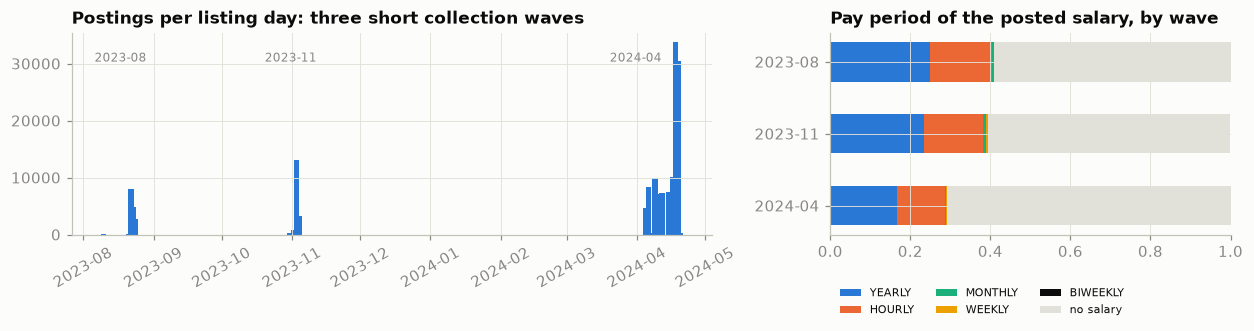

In [3]:
wave_tbl = posts.groupby("wave").agg(
    postings=("job_id", "size"), first=("listed_time", "min"), last=("listed_time", "max"),
    collection_days=("listed_time", lambda s: s.dt.date.nunique()),
    top2_days_share=("listed_time", lambda s: s.dt.date.value_counts().head(2).sum() / len(s)),
    distinct_texts=("desc_hash", "nunique"), with_salary=("pay_period", lambda s: s.notna().mean()),
    with_label=("functions", lambda s: (s != "").mean()))
wave_tbl["repeated_text"] = 1 - wave_tbl.distinct_texts / wave_tbl.postings
display(wave_tbl.style.format({"postings": "{:,}", "distinct_texts": "{:,}", "first": "{:%d %b %Y}", "last": "{:%d %b %Y}",
                               "top2_days_share": "{:.0%}", "with_salary": "{:.0%}", "with_label": "{:.0%}", "repeated_text": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
daily = posts.groupby(posts.listed_time.dt.floor("D")).size()
ax.bar(daily.index, daily.values, width=2.5, color=SERIES[0])
for w, (a, b) in WAVES.items():
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=5), daily.max() * 0.9, w, color=MUTED, fontsize=8)
ax.set_title("Postings per listing day: three short collection waves"); ax.tick_params(axis="x", rotation=30)
ax = axes[1]
mix = pd.crosstab(posts.wave, posts.pay_period.fillna("no salary"), normalize="index")
order = ["YEARLY", "HOURLY", "MONTHLY", "WEEKLY", "BIWEEKLY", "no salary"]
mix = mix[[c for c in order if c in mix.columns]]
left = np.zeros(len(mix))
palette = {"YEARLY": SERIES[0], "HOURLY": SERIES[1], "MONTHLY": SERIES[2], "WEEKLY": SERIES[3], "BIWEEKLY": INK, "no salary": GRID}
for c in mix.columns:
    ax.barh(mix.index, mix[c], left=left, color=palette[c], label=c, height=0.55); left += mix[c].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title("Pay period of the posted salary, by wave"); ax.legend(fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, -0.45))
plt.tight_layout()

lab = posts[posts.functions != ""].functions.str.split("|")
print(f"LinkedIn 'skill' labels: {lab.explode().nunique()} distinct values, {lab.str.len().value_counts().sort_index().to_dict()} labels per posting; "
      f"{(posts.functions == '').sum():,} postings without one and {posts.orphan_labels.iloc[0]:,} label rows whose posting is missing")
print("the ten most common, April 2024:", ", ".join(f"{FUNC_NAME[k]} {v:.0%}" for k, v in
      posts[posts.wave == "2024-04"].functions.str.split("|").explode().value_counts(normalize=True).head(10).items()))
print("skills_desc field:", posts.skills_desc_kind.value_counts().to_dict())
print(f"busiest listing day: {daily.idxmax():%d %b %Y} ({daily.max():,} postings)")
apr_t = posts.listed_time[posts.wave == "2024-04"]; in_apr = apr_t >= "2024-04-01"
print(f"April wave: {(~in_apr).sum()} posting listed in March; the other {in_apr.sum():,} on {apr_t[in_apr].dt.date.nunique()} days, "
      f"{apr_t[in_apr].min():%d}–{apr_t.max():%d %B %Y}")

The "time series" is three bursts: ten listing days in August 2023, five around 1 November and twelve in April 2024 (plus one posting dated 24 March), with 52 % of April's postings listed on two days. The share with a salary falls from 41 % to 29 %, and the pay-period mix shifts with it. LinkedIn's label is one of 35 values, at most three per posting. Each of these becomes a trap in Section 6.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Skill extraction without an LLM: rules propose, a dictionary decides

*Part B · Given model · package `candidates`, `trie_regex`, `scan` and `prf` with the frozen dictionary; reproduce F1 0.62 (C2).*

No LLM, on purpose: a dictionary is cheap, explainable and versioned like a model. **Candidate rules** find the phrases after cues such as "experience with" and split them into items of one to four words; **the dictionary** decides which candidates, and which other mentions, are skills.

It was seeded from the August 2023 wave only (the most over-represented candidates per LinkedIn label, two cells down), curated by the author into 138 skills and debugged on that wave. Boilerplate traps found that way became rules or removed forms: "EEO" statements, "recruitment process", "Salesforce" in postings *by* Salesforce, "excel" the verb.

In [4]:
SKILL_TABLE = """
Python | digital | Python | ccd0a1d9 | exact
SQL | digital | SQL; SQL Server; MySQL; PostgreSQL; Postgres; T-SQL; PL/SQL; Transact-SQL | 598de5b0 | exact
NoSQL databases | digital | NoSQL; MongoDB; Cassandra; DynamoDB; Cosmos DB | 76ef6ed3 | exact
Java | digital | Java; J2EE; Spring Boot; Spring Framework | 19a8293b | exact
JavaScript | digital | JavaScript; Node.js; NodeJS; jQuery | 3cd569a2 | exact
TypeScript | digital | TypeScript | 867137fb | exact
C++ | digital | C++ | b633eb55 | exact
C# and .NET | digital | C#; .NET; ASP.NET; .NET Core | 4c016b68 | close
HTML and CSS | digital | HTML; HTML5; CSS; CSS3 | 0af062de | close
React | digital | React; ReactJS; React.js; React Native | 9b9de2a4 | broad
Angular | digital | Angular; AngularJS | 9b9de2a4 | broad
Git | digital | Git; GitHub; GitLab; Bitbucket; version control | 9d2e926f | broad
Docker | digital | Docker; containerization; containerisation | f0de4973 | broad
Kubernetes | digital | Kubernetes; K8s; OpenShift | f0de4973 | broad
CI/CD and DevOps | digital | CI/CD; DevOps; continuous integration; continuous delivery; continuous deployment; Jenkins; GitHub Actions | f0de4973 | close
Infrastructure as code | digital | Terraform; Ansible; CloudFormation; infrastructure as code; Puppet | 6f8a40d6 | narrow
AWS | digital | AWS; Amazon Web Services; EC2; S3 | bd14968e | broad
Microsoft Azure | digital | Azure; Microsoft Azure | bd14968e | broad
Google Cloud | digital | GCP; Google Cloud; Google Cloud Platform; BigQuery | bd14968e | broad
Linux and Unix | digital | Linux; Unix; Red Hat; RHEL; Ubuntu | 35f1be97 | broad
Scripting | digital | PowerShell; Bash; shell scripting; scripting languages; Perl | 5ef0c719 | close
Computer networking | digital | TCP/IP; DNS; DHCP; LAN; WAN; VPN; VLAN; routing and switching; Cisco; firewalls; network protocols; networking protocols | 6e4f75b4 | close
Active Directory | digital | Active Directory; Windows Server; Group Policy; LDAP | d1e954cd | close
Cybersecurity | digital | cybersecurity; cyber security; information security; network security; SIEM; vulnerability management; penetration testing; incident response; NIST | 8088750d | exact
Machine learning | digital | machine learning; deep learning; TensorFlow; PyTorch; scikit-learn; neural networks; natural language processing; NLP; computer vision | 8369c2d6 | exact
Data analysis | digital | data analysis; data analytics; statistical analysis; data mining | 2b92a5b2 | exact
Statistics | digital | statistics; statistical modeling; statistical modelling; regression analysis; SAS; SPSS; Stata | 7ee4c2ea | exact
R | digital | RStudio; R Studio; R programming; Python and R; Python or R; R and Python; R or Python; Python, R; R, Python; SQL, R; R, SQL; SAS, R; R, SAS | 51586df8 | exact
Tableau | digital | Tableau | 143769cb | broad
Power BI | digital | Power BI; PowerBI | 143769cb | broad
Data visualisation | digital | data visualization; data visualisation; Looker; Qlik | c3e36d05 | close
Data warehousing and ETL | digital | ETL; ELT; data warehousing; data warehouse; Snowflake; Redshift; data pipelines; Informatica; SSIS | 3ec2e4d6 | close
Big data | digital | Apache Spark; PySpark; Spark SQL; Databricks; Hadoop; Kafka; Apache Kafka; Hive; big data | 47a49cd6 | close
Data modelling | digital | data modeling; data modelling; data models | fecf8a0d | exact
APIs and web services | digital | RESTful; REST API; REST APIs; REST services; web services; SOAP; microservices; API development; API integration; APIs; GraphQL | b0096dc5 | close
Agile and Scrum | digital | Agile methodology; Agile methodologies; Agile development; Agile environment; Agile framework; Agile practices; Agile principles; Scrum; Kanban; sprint planning | 0a9acb6b | close
Jira and Confluence | digital | Jira; Confluence; Atlassian | - | none
Software testing | digital | software testing; test automation; automated testing; Selenium; unit testing; QA automation; Cypress; JUnit; pytest; regression testing | 913e7e83 | close
IT service management | digital | ITIL; ITSM; IT service management; ServiceNow | d12e9d68 | close
Technical support | digital | technical support; desktop support; help desk; helpdesk; service desk; end user support | c2296e2e | exact
Troubleshooting | transversal | troubleshooting; troubleshoot | 334e3e49 | exact
ERP systems | digital | SAP; ERP; ERP systems; enterprise resource planning; Oracle ERP; NetSuite; Microsoft Dynamics; Dynamics 365; JD Edwards; PeopleSoft | f0393af3 | close
CRM and Salesforce | digital | Salesforce; CRM; CRM software; CRM systems; HubSpot; customer relationship management | 9889b795 | close
Microsoft Excel | office | Excel; MS Excel; Microsoft Excel; spreadsheets; spreadsheet; pivot tables; VLOOKUP | 1973c966 | close
Microsoft Office | office | Microsoft Office; MS Office; Office Suite; Office 365; Microsoft 365; MS Word; Microsoft Word; word processing; PowerPoint; Microsoft Outlook; MS Outlook; Microsoft Teams; Visio; SharePoint; office applications; office products; office programs; office software; Word, Excel; Excel, Word; Word and Excel; Excel and Word; , Outlook; Outlook, | f683ae1d | exact
Google Workspace | office | Google Suite; G Suite; Google Workspace; Google Docs; Google Sheets | cf310cff | broad
Data entry | office | data entry; typing; keyboarding; 10-key; ten key | d181042e | close
Accounting | business | accounting; bookkeeping; general ledger; journal entries; account reconciliation; account reconciliations; reconciliations; month-end close; month end close; cost accounting | ecc18804 | exact
GAAP and IFRS | business | GAAP; US GAAP; generally accepted accounting principles; IFRS | d0c425c6 | close
Accounting software | business | QuickBooks; accounting software; Xero; Sage Intacct | a0d79341 | close
Accounts payable and receivable | business | accounts payable; accounts receivable; AP/AR; invoice processing; invoicing | 68b51538 | close
Auditing | business | auditing; internal audit; internal controls; SOX; Sarbanes-Oxley; audit procedures; external audit | 6a536b36 | close
Financial analysis | business | financial analysis; financial modeling; financial modelling; FP&A; financial planning and analysis; variance analysis; valuation; discounted cash flow | 99571e68 | exact
Budgeting and forecasting | business | budgeting; budget management; forecasting; budget preparation; budget development | 21c5790c | close
Financial reporting | business | financial reporting; financial statements; financial statement preparation | 4a460161 | close
Tax | business | tax preparation; taxation; tax compliance; tax returns; tax accounting | 22a173f5 | close
Payroll | business | payroll; payroll processing | 9d916d7c | exact
Lending and underwriting | business | underwriting; loan processing; mortgage lending; credit analysis; loan origination | 872bde22 | close
Risk management | business | risk management; risk assessment; risk assessments; risk analysis | 6eff134b | exact
Financial crime compliance | business | AML; anti-money laundering; KYC; BSA; Bank Secrecy Act; regulatory compliance | f5afbe94 | close
Business analysis | business | business analysis; requirements gathering; requirements analysis; business requirements; user stories; process mapping; BPMN; use cases | 633a3637 | exact
Project management | business | project management; project planning; PMP; Microsoft Project; MS Project; Smartsheet; project management software; project management tools; project management methodologies; PMBOK; project scheduling | 7111b95d | exact
Change management | business | change management; organizational change; organisational change | 3c03ee71 | exact
Strategic planning | business | strategic planning; strategy development; business planning | 949ced5f | exact
Process improvement | business | process improvement; continuous improvement; business process improvement; root cause analysis | 958b8802 | close
Sales techniques | business | cold calling; prospecting; lead generation; consultative selling; solution selling; closing sales; upselling; up-selling; cross-selling; sales techniques; selling skills; pipeline management | e7219848 | close
Account management | business | account management; key account management; client relationship management; relationship management; business development | 2239694b | close
Negotiation | transversal | negotiation; negotiating; negotiation skills | - | none
Customer service | transversal | customer service; customer support; client service; customer care | 15a33d76 | exact
Digital marketing | business | digital marketing; online marketing; email marketing; marketing automation; paid media; PPC; pay-per-click; Google Ads; SEM; paid search; paid social | 43dfbe7f | exact
SEO | business | SEO; search engine optimization; search engine optimisation | eda4d727 | exact
Social media marketing | business | social media marketing; social media management; social media platforms; social media content; social media strategy; social media channels | 5303169c | exact
Web analytics | business | Google Analytics; web analytics; Adobe Analytics; Google Tag Manager | 1605025e | exact
Content and copywriting | business | content creation; copywriting; content writing; content marketing; content strategy; copy editing; copyediting; proofreading | ce592b28 | close
Market research | business | market research; market analysis; competitive analysis; consumer research; competitor analysis | 8770350e | exact
Public relations | business | public relations; media relations; press releases | 5330b70e | exact
Product management | business | product management; product roadmap; product roadmaps; product lifecycle; go-to-market; product strategy | 29fb886c | close
Event planning | business | event planning; event management; event coordination | a4b7f1be | exact
Patient care | healthcare | patient care; direct patient care; bedside care; patient assessment; patient assessments | 24f980ba | close
Medical terminology | healthcare | medical terminology | 2806260f | exact
Electronic health records | healthcare | electronic medical records; electronic medical record; electronic health records; electronic health record; EMR; EHR; EHRs; EMRs; Epic Systems; Cerner; Meditech | 53141450 | exact
CPR and life support | healthcare | CPR; BLS; ACLS; PALS; basic life support; advanced cardiac life support; first aid; AED | 8bd49d04 | close
Medication administration | healthcare | medication administration; administer medications; administering medications; administer medication; medication management; medication pass; med pass | 1fd57242 | exact
Phlebotomy | healthcare | phlebotomy; venipuncture; venepuncture; blood draws; blood draw; specimen collection | 0646be77 | exact
Vital signs | healthcare | vital signs | 60f826be | exact
Nursing licence | healthcare | RN license; RN licensure; registered nurse license; LPN license; licensed practical nurse; LVN; nursing license; nursing licensure; CNA certification; certified nursing assistant | - | none
Medical billing and coding | healthcare | medical billing; medical coding; ICD-10; CPT; HCPCS; billing and coding; revenue cycle | cf0b92de | close
HIPAA | healthcare | HIPAA | 51ece34f | close
Infection control | healthcare | infection control; infection prevention; sterile technique; aseptic technique | 6d13053b | exact
Case management | healthcare | case management; care coordination; discharge planning | 2ffc7a73 | exact
Crisis intervention | healthcare | crisis intervention; de-escalation; crisis management | 8e261d1c | close
Personal care | healthcare | activities of daily living; ADLs; ADL; personal care; elder care; home care | 6f2ac3e9 | close
Anatomy and physiology | healthcare | anatomy; physiology | 9ec4252d | close
HVAC | technical | HVAC; HVAC/R; HVACR; refrigeration | aba2e61d | close
Electrical systems | technical | electrical systems; electrical wiring; electrical troubleshooting; electrical maintenance; National Electrical Code; NEC; electrical codes; electrical schematics; low voltage; high voltage; wiring | c8ac1986 | close
Plumbing | technical | plumbing; pipefitting | 8755734c | close
Carpentry | technical | carpentry | 19858dd3 | exact
Welding | technical | welding; MIG; TIG; arc welding; brazing | 530cb489 | exact
Power and hand tools | technical | power tools; hand tools | 5bf7f85a | close
Forklift and material handling | technical | forklift; forklifts; pallet jack; material handling; reach truck; order picker | 28cb374e | close
Lean and Six Sigma | technical | lean manufacturing; lean principles; lean six sigma; six sigma; kaizen; 5S; value stream mapping; lean methodology; lean methodologies | 0550431f | close
Quality management | technical | quality control; quality assurance; ISO 9001; GMP; cGMP; good manufacturing practice; good manufacturing practices; QA/QC; statistical process control; SPC | c7cc6dc5 | close
Workplace safety | technical | OSHA; safety regulations; workplace safety; occupational safety; occupational health and safety; EHS; lockout/tagout; lockout tagout; LOTO; hazmat; hazardous materials | 198b614d | exact
Technical drawings | technical | blueprints; blueprint reading; schematics; technical drawings; engineering drawings; GD&T | b07daddc | close
CAD | technical | AutoCAD; CAD; computer-aided design; SolidWorks; CATIA; Creo; MicroStation; Civil 3D | a2b5dcf3 | exact
BIM and Revit | technical | Revit; BIM; building information modeling; building information modelling | a2b5dcf3 | broad
PLC and automation | technical | PLC; PLCs; programmable logic controllers; programmable logic controller; SCADA; HMI; ladder logic; industrial automation | 6468e5fb | exact
CNC and machining | technical | CNC; machining; lathe; milling machine; Mastercam; G-code | bf942c60 | close
Hydraulics and pneumatics | technical | hydraulics; hydraulic systems; pneumatics; pneumatic systems | 68e66ed6 | close
Preventive maintenance | technical | preventive maintenance; preventative maintenance; predictive maintenance | 8a4e99e0 | close
Inventory management | logistics | inventory management; inventory control; stock control; cycle counts; cycle counting | ab6265f2 | exact
Supply chain and logistics | logistics | supply chain; supply chain management; logistics; warehouse operations; shipping and receiving; distribution operations | f929c89e | close
Procurement | logistics | procurement; purchasing; strategic sourcing; vendor management; supplier management | 9e9a4209 | close
Commercial driving | logistics | CDL; commercial driver's license; commercial drivers license; Class A CDL; DOT regulations | 2a82241a | broad
Construction management | technical | construction management; Procore; building codes; construction estimating; cost estimating; construction scheduling | 615cfc39 | narrow
Food safety | technical | food safety; ServSafe; food handling; food handler; HACCP | 3f4e4eab | exact
Cash handling and POS | business | cash handling; point of sale; point-of-sale; POS system; POS systems; cash register | 0cb013af | close
Recruiting | people | full-cycle recruiting; full cycle recruiting; talent acquisition; sourcing candidates; candidate sourcing; applicant tracking system; applicant tracking systems; recruiting experience; recruitment experience; technical recruiting | 65715f7a | exact
HRIS | people | HRIS; Workday HCM; human resources information system; human resources information systems; UKG; SuccessFactors; BambooHR | - | none
Employee relations | people | employee relations; labor relations; labour relations | 1212ac42 | close
Compensation and benefits | people | benefits administration; compensation analysis; compensation programs; compensation planning | a4e50b95 | close
Employment law | people | employment law; employment laws; labor laws; labor law; labour law; labor and employment law | 97b713f0 | exact
Instructional design | people | instructional design; curriculum development; e-learning; elearning; learning management system; learning management systems; LMS; Articulate Storyline; Moodle | e3145bd7 | close
Teaching | people | lesson planning; lesson plans; classroom management; differentiated instruction; special education; IEP; IEPs; tutoring | cedd0710 | close
Legal research and litigation | people | litigation; legal research; legal writing; e-discovery; ediscovery; contract drafting; contract review; contract law; Westlaw; LexisNexis | a8585efe | close
Adobe Creative Suite | design | Adobe Creative Suite; Adobe Creative Cloud; Photoshop; Illustrator; InDesign; After Effects; Premiere Pro; Adobe Premiere; Lightroom | 1bc718b6 | exact
Graphic design | design | graphic design; typography; layout design; visual design; Canva | 7fb699d9 | exact
UX/UI design | design | UX; UI/UX; UX/UI; user experience; user interface design; UI design; UX design; Figma; wireframing; wireframes; prototyping; usability testing; user research | fd33c66c | close
Technical writing | design | technical writing; technical documentation; technical writer | 04dfd9fb | close
Communication | transversal | communication skills; written communication; verbal communication; oral communication; written and verbal; verbal and written; written and oral; oral and written; interpersonal skills; interpersonal communication | 15d76317 | exact
Presentation skills | transversal | presentation skills; public speaking; deliver presentations; delivering presentations | fd446407 | close
Teamwork | transversal | teamwork; team player; team-oriented; team oriented; work collaboratively; work as part of a team; work well in a team | 60c78287 | exact
Problem solving | transversal | problem solving; problem-solving; critical thinking; analytical skills; analytical thinking | b9f16465 | close
Leadership | transversal | leadership skills; leadership ability; leadership abilities; leadership experience; people management; team leadership; supervisory experience; supervisory skills; mentoring | 75d8e5d9 | close
Time management | transversal | time management; organizational skills; organisational skills; prioritization; prioritisation; multitasking; multi-tasking; multi-task; ability to prioritize; ability to multitask | d9013e0e | close
Attention to detail | transversal | attention to detail; detail-oriented; detail oriented | 59f56593 | exact
Spanish | transversal | Spanish; bilingual | 14ee9f76 | close
Driving licence | transversal | driver's license; drivers license; driver license; driving license; driving record; motor vehicle record | 2a82241a | close
"""
skills = pd.DataFrame([dict(zip(["skill", "kind", "forms", "esco", "match"], [x.strip() for x in line.split("|")]))
                       for line in SKILL_TABLE.strip().splitlines()])
skills["forms"] = skills.forms.str.split(";").map(lambda f: [x.strip() for x in f if x.strip()])
SKILLS = list(skills.skill); S_IDX = {s: i for i, s in enumerate(SKILLS)}
assert skills.skill.is_unique and skills.kind.isin(["digital", "office", "business", "healthcare", "technical", "logistics",
                                                   "people", "design", "transversal"]).all()
print(f"dictionary v1: {len(skills)} skills, {skills.forms.map(len).sum()} written surface forms; kinds {skills.kind.value_counts().to_dict()}")

dictionary v1: 138 skills, 796 written surface forms; kinds {'digital': 42, 'business': 30, 'technical': 19, 'healthcare': 15, 'transversal': 12, 'people': 8, 'office': 4, 'logistics': 4, 'design': 4}


In [5]:
CTX = re.compile(r"(?:experience|experienced|proficien\w*|knowledge|familiar\w*|expertise|skilled|skills?|certifi\w*|competen\w*|"
                 r"understanding|background|fluen\w*|trained|training)\s+(?:with|in|of|on|using|including|such as)\s+([^.;:!?()\[\]•·]{2,120})")
SPLIT = re.compile(r",|\band\b|\bor\b|/|&|\betc\b|\bincluding\b|\bsuch as\b|\bas well as\b|\be\.g\b|\bi\.e\b")
LEAD = re.compile(r"^(?:(?:a|an|the|strong|basic|working|advanced|excellent|good|general|solid|proven|relevant|related|various|other|"
                  r"common|standard|modern|using|use of|in|of|with|any|all|some|one|two|three|several|demonstrated|thorough|sound|deep|"
                  r"practical|hands-on|hands on|applicable|appropriate|current|similar|previous|prior|professional|technical|computer|ms|microsoft)\s+)+")
GENERIC = set("""procedures tools field practices regulations software services systems products applications policies state one development
technology processes principles techniques business equipment operations industry standards methods concepts areas experience skills
knowledge role related environment environments work preferred fields programs program project projects management data designing
developing design documentation requirements solutions support service process system tool tasks task duties functions teams team staff
people customers clients ability abilities understanding following more least degree years year job position technologies platforms
platform languages language frameworks framework methodologies approaches activities laws rules guidelines federal local area office
computers computer best basic etc information trends issues others""".split())

def candidates(text: str) -> list:
    '''Rule 1: phrases after 'experience with', 'knowledge of', 'proficiency in' …, split into items of one to four words.'''
    out = []
    for m in CTX.finditer(text):
        for item in SPLIT.split(m.group(1)):
            item = LEAD.sub("", item.strip(" -*'\"")).strip(" -*'\"")
            words = item.split()
            if 1 <= len(words) <= 4 and len(item) >= 2 and not item.isdigit() and not all(w in GENERIC for w in words):
                out.append(item)
    return out

def norm_form(s: str) -> str:
    return normalise(pa.array([s])).to_pylist()[0].strip()

def trie_regex(words) -> str:
    '''One alternation shaped as a character trie, so the longest surface form wins and matching stays fast.'''
    trie = {}
    for w in words:
        node = trie
        for ch in w:
            node = node.setdefault(ch, {})
        node[""] = True
    def build(node):
        if "" in node and len(node) == 1:
            return ""
        alts = [re.escape(ch) + build(node[ch]) for ch in sorted(k for k in node if k)]
        s = alts[0] if len(alts) == 1 else "(?:" + "|".join(alts) + ")"
        return "(?:" + s + ")?" if "" in node else s
    return build(trie)

class Extractor:
    '''Dictionary matcher plus three rules: 'excel' the verb, the employer's own name, React without a web stack.'''
    def __init__(self, extra_forms=None, table=None):
        self.form2skill = {}
        for r in (skills if table is None else table).itertuples():
            for f in r.forms + (extra_forms or {}).get(r.skill, []):
                for v in {norm_form(f), " ".join(f.lower().split())}:
                    self.form2skill.setdefault(v, r.skill)
        self.pat = re.compile(r"(?<![a-z0-9+#])(" + trie_regex(self.form2skill) + r")(?![a-z0-9+#])")

    def find(self, text: str, company: str = "") -> set:
        found = set()
        for m in self.pat.finditer(text):
            f = m.group(1)
            if f == "excel" and (text[m.end():m.end() + 4] in (" in ", " at ", " as ") or
                                 text[max(0, m.start() - 6):m.start()].split()[-1:] in (["to"], ["we"], ["you"], ["will"], ["can"], ["help"])):
                continue                                          # the verb, not the spreadsheet
            if company and f" {f} " in f" {company} ":
                continue                                          # the employer's own name ('salesforce' at Salesforce)
            found.add(self.form2skill[f])
        if "React" in found and not found & {"JavaScript", "TypeScript", "HTML and CSS"}:
            found.discard("React")
        return found

    def places(self, item: str) -> bool:
        return self.pat.search(item) is not None

base = Extractor()
print(f"dictionary-only extractor: {len(base.form2skill):,} normalised surface forms")

dictionary-only extractor: 812 normalised surface forms


The text work runs on at most 15,000 distinct descriptions per wave, drawn with the seed; copies share their skills, so the distinct description is the unit (Trap 1).

In [6]:
GOLD_TEXT = """
3885108959: Payroll; Data entry; HRIS; Compensation and benefits; Auditing; Attention to detail; Microsoft Excel; Microsoft Office; Communication; Customer service
3899527890: Accounts payable and receivable; Accounting software; Accounting; Microsoft Excel; Financial reporting; Attention to detail; Customer service; Negotiation; +mathematics
3905237784: Financial crime compliance; Risk management; Auditing; Leadership; +regulatory reporting; +Global Vision software
3905302460: Tax; Leadership; Communication; Account management; Strategic planning; +CPA licence
3905801100: Accounts payable and receivable; Auditing; Accounting; Microsoft Excel; Accounting software; +telecom billing and tariffs
3889109981: Nursing licence; +medical-surgical nursing
3889745411: Patient care; CPR and life support; Communication; Time management; Leadership; +occupational therapy
3903810194: Nursing licence; Electronic health records; Microsoft Office; Quality management; +patient safety
3904992682: Leadership; Patient care; +nursing management
3906093209: Nursing licence; CPR and life support; Customer service; Attention to detail; Time management; Leadership; Patient care; +clinical documentation
3878193413: Technical support; Troubleshooting; Customer service; Teamwork; +Microsoft Exchange; +ticketing systems; +CJIS certification
3901377139: ERP systems; Change management; Business analysis; Software testing; +PLM (Teamcenter); +bills of materials
3901559680: Account management; Sales techniques; Communication; Problem solving; +power and UPS products
3904725092: Construction management; Technical drawings; Communication; Time management; Attention to detail; Driving licence; +building inspection
3905209347: C# and .NET; C++; SQL; Active Directory; APIs and web services; Computer networking; Agile and Scrum; Git; +distributed systems; +object-oriented design; +IIS
3878803731: Leadership; Cash handling and POS; Customer service; Food safety; Preventive maintenance; Procurement; Budgeting and forecasting
3895524437: Communication; Customer service; Time management; +collision repair; +ASE certification
3904038477: Supply chain and logistics; Inventory management; Budgeting and forecasting; Microsoft Excel; Communication; Teamwork; Problem solving; ERP systems; Procurement; Project management; +demand planning (S&OP)
3904922433: Workplace safety; Risk management; Data analysis; Problem solving; Communication; Microsoft Office; Microsoft Excel; Time management; Teamwork; Driving licence; Technical writing; Presentation skills; +ergonomics
3905332306:
3901352863: Project management; Budgeting and forecasting; Risk management; Communication; Time management; Leadership; Workplace safety; +commissioning
3902784304: Leadership; Problem solving; Budgeting and forecasting; Food safety; +culinary arts; +menu planning
3903428592: Project management; Construction management; Budgeting and forecasting; Quality management; Risk management; Change management; Financial reporting; Communication; Time management; Teamwork; Microsoft Office; +contract administration
3903494723: Project management; Budgeting and forecasting; Communication; Presentation skills; +drug development; +pharmaceutical regulatory compliance; +performance measurement
3904988047: Construction management; Project management; Budgeting and forecasting; Negotiation; Communication; Leadership; Teamwork; Attention to detail; Driving licence; Technical drawings; +mathematics; +mechanical knowledge
3895531350: Customer service; Leadership; Financial analysis; Problem solving; Sales techniques; +visual merchandising; +mathematics
3901944587: +grief counselling; +group facilitation; +suicide risk assessment; +social work
3904061129: Communication; Customer service; +reservations
3904392588: Leadership; +assembly line operations
3905861146: Graphic design; Adobe Creative Suite; Attention to detail; Project management; Time management; Technical writing; +QuarkXPress; +content management systems
3887996330: Sales techniques; CRM and Salesforce; Microsoft Office; Google Workspace; Communication; +call centre experience
3901996791: Sales techniques; Presentation skills; Negotiation; Account management; Customer service; Communication
3902321529: Sales techniques; Budgeting and forecasting; CRM and Salesforce; Microsoft Office; Problem solving; Account management
3903443825: Sales techniques; Presentation skills; Account management; Leadership; Communication; Time management; Microsoft Excel; Microsoft Office; Driving licence; Teamwork; +bids and price quotes
3904365444: Customer service; Communication; Microsoft Office; Microsoft Excel; Technical support; +A/B testing; +multi-channel support
3887717110: Legal research and litigation; +bar admission; +depositions
3889417418: Medical terminology; Data entry; Communication; HIPAA; +patient scheduling; +phone etiquette
3889708733: Attention to detail; +database record updates; +web browser use
3891251879: Teaching; Leadership; Time management; Communication; Teamwork; +child development; +CDA credential
3905312401: Recruiting; Employment law; Employee relations; Leadership; Communication; Time management; Teamwork; +onboarding; +performance management; +conflict resolution
"""
GOLD = {int(j): {x.strip() for x in labs.split(";") if x.strip()}
        for j, labs in (line.split(":", 1) for line in GOLD_TEXT.strip().splitlines())}
GENAI = re.compile(r"\b(?:generative ai|gen ?ai|large language models?|llms?|chat ?gpt|prompt engineering)\b")

# one row per distinct description within a wave; the text sample is drawn from these (the earliest listing is kept)
dist = posts.sort_values("listed_time").drop_duplicates(["wave", "desc_hash"])
sample = pd.concat([d.sample(min(N_PER_WAVE, len(d)), random_state=SEED) for _, d in dist.groupby("wave")]).reset_index(drop=True)
COMPANY = posts[posts.job_id.isin(set(sample.job_id) | set(GOLD))].set_index("job_id").company_key.to_dict()
res = {}

def scan(ex, key: str, ids, first_pass: bool = False):
    '''Stream the cached text once: skills for one extractor, plus (first pass) candidate phrases and the gen-AI flag.'''
    want = pa.array(sorted(ids), pa.int64())
    for batch in pq.ParquetFile(TEXT_PATH).iter_batches(batch_size=10_000):
        b = batch.filter(pc.is_in(batch.column(0), value_set=want))
        for j, t in zip(b.column(0).to_pylist(), b.column(1).to_pylist()):
            r = res.setdefault(j, {})
            if first_pass:
                r["cand"], r["genai"] = candidates(t), GENAI.search(t) is not None
            r[key] = ex.find(t, COMPANY.get(j, ""))
            r["unplaced_" + key] = [x for x in r["cand"] if not ex.places(x)]

t0 = time.time()
scan(base, "base", set(sample.job_id) | set(GOLD), first_pass=True)
print(f"scanned {len(res):,} distinct descriptions ({sample.wave.value_counts().sort_index().to_dict()} plus the gold set) in {time.time()-t0:.0f}s, "
      f"{1000 * (time.time()-t0) / len(res):.1f} ms per posting including the candidate rules")

def to_matrix(ids, key="base"):
    rows, cols = [], []
    for i, j in enumerate(ids):
        for s in res[j].get(key, ()):
            rows.append(i); cols.append(S_IDX[s])
    return sp.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(len(ids), len(SKILLS)))

X = to_matrix(sample.job_id)
sample["n_skills"] = np.asarray(X.sum(axis=1)).ravel()
print(f"skills per posting: median {sample.n_skills.median():.0f}, none found in {(sample.n_skills == 0).mean():.1%} of postings")

scanned 43,864 distinct descriptions ({'2023-08': 13831, '2023-11': 15000, '2024-04': 15000} plus the gold set) in 23s, 0.5 ms per posting including the candidate rules
skills per posting: median 4, none found in 6.1% of postings


In [7]:
# Seeding, reproduced: the candidate phrases most over-represented under each LinkedIn label in the seed wave
seed = sample[sample.wave == SEED_WAVE]
cnt_all, cnt_f, n_f = Counter(), defaultdict(Counter), Counter()
for j, fs in zip(seed.job_id, seed.functions):
    c = set(res[j]["cand"]); cnt_all.update(c)
    for f in (fs.split("|") if fs else []):
        cnt_f[f].update(c); n_f[f] += 1

def seeds(f, min_count=6, min_lift=2.0):
    rows = []
    for k, v in cnt_f[f].items():
        lift = (v / n_f[f]) / (cnt_all[k] / len(seed))
        if v >= min_count and lift >= min_lift:
            rows.append((v * np.log(lift), k))
    return [k for _, k in sorted(rows, reverse=True)]

seed_lists = {f: seeds(f) for f in n_f}
n_seeds = len({k for v in seed_lists.values() for k in v})
display(pd.DataFrame({FUNC_NAME[f]: pd.Series(seed_lists[f][:8], dtype=object) for f in ["IT", "ACCT", "HCPR", "MNFC"]}).fillna(""))
covered = np.mean([base.places(k) for k in {k for v in seed_lists.values() for k in v}])
print(f"{sum(cnt_all.values()):,} candidate mentions in {len(seed):,} seed-wave postings; {n_seeds:,} distinct seeds pass "
      f"(count ≥ 6, lift ≥ 2 for some label); the curated dictionary places {covered:.0%} of them")

,Information Technology,Accounting/Auditing,Health Care Provider,Manufacturing
0,python,accounting,medical terminology,hotel
1,sql,gaap,nursing theory,electrical
2,java,accounting principles,families,plumbing
3,java script,accounting software,clinical area,warehouse
4,azure,excel,caregiver,food
5,aws,public accounting,age group served,hvac
6,css,finance,hospital,warehouse operations
7,ci,generally accepted accounting principles,physiology,mvr recor


63,095 candidate mentions in 13,831 seed-wave postings; 620 distinct seeds pass (count ≥ 6, lift ≥ 2 for some label); the curated dictionary places 35% of them


**Evaluation, twice.** First against 40 hand-labelled April postings (five per label group, 700–3,500 characters, drawn with the seed): every skill the posting asks for or the role clearly performs, in dictionary names or free text (`+`). Then against LinkedIn's label, through each skill's "home" label (where it is most over-represented in the seed wave).

In [8]:
def prf(pred: dict, gold: dict) -> dict:
    tp = sum(len(pred[j] & gold[j]) for j in gold)
    fp = sum(len(pred[j] - gold[j]) for j in gold)
    fn = sum(len(gold[j] - pred[j]) for j in gold)
    in_dict = sum(len({g for g in gold[j] if not g.startswith("+")}) for j in gold)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"precision": p, "recall": r, "F1": 2 * p * r / max(p + r, 1e-9), "recall (in-dictionary labels)": tp / max(in_dict, 1),
            "labels": tp + fn, "predicted": tp + fp}

gold_eval = prf({j: res[j]["base"] for j in GOLD}, GOLD)
n_out = sum(g.startswith("+") for v in GOLD.values() for g in v)
print(f"hand-labelled set: {len(GOLD)} April 2024 postings, {gold_eval['labels']} skill labels, {n_out} of them ({n_out/gold_eval['labels']:.0%}) "
      f"with no dictionary entry · SHA-256 {hashlib.sha256(GOLD_TEXT.encode()).hexdigest()[:12]}")
display(pd.Series(gold_eval).to_frame("dictionary v1").T.style.format({"precision": "{:.2f}", "recall": "{:.2f}", "F1": "{:.2f}",
                                                                          "recall (in-dictionary labels)": "{:.2f}"}))
cnt = np.array([[len(res[j]["base"] & GOLD[j]), len(res[j]["base"] - GOLD[j]), len(GOLD[j] - res[j]["base"])] for j in GOLD])
r_ = np.random.default_rng(SEED); f1_boot = []
for _ in range(1000):
    tp, fp, fn = cnt[r_.integers(0, len(cnt), len(cnt))].sum(0)
    f1_boot.append(2 * tp / (2 * tp + fp + fn))
print(f"F1 95% interval, resampling the 40 postings: {np.percentile(f1_boot, 2.5):.2f}–{np.percentile(f1_boot, 97.5):.2f}")
fp_pairs = Counter(s for j in GOLD for s in res[j]["base"] - GOLD[j])
fn_pairs = Counter(s for j in GOLD for s in GOLD[j] - res[j]["base"] if not s.startswith("+"))
print("false positives:", dict(fp_pairs.most_common(8)))
print("missed in-dictionary labels:", dict(fn_pairs.most_common(8)))

hand-labelled set: 40 April 2024 postings, 267 skill labels, 58 of them (22%) with no dictionary entry · SHA-256 79fda90a296b


,precision,recall,F1,recall (in-dictionary labels),labels,predicted
dictionary v1,0.94,0.46,0.62,0.59,267.000000,131.000000


F1 95% interval, resampling the 40 postings: 0.54–0.68
false positives: {'Legal research and litigation': 1, 'Customer service': 1, 'Personal care': 1, 'Quality management': 1, 'Teamwork': 1, 'Instructional design': 1, 'Risk management': 1, 'Supply chain and logistics': 1}
missed in-dictionary labels: {'Leadership': 12, 'Communication': 8, 'Time management': 6, 'Budgeting and forecasting': 6, 'Teamwork': 5, 'Presentation skills': 4, 'Account management': 3, 'Sales techniques': 3}


In [9]:
# Against the structured field: each skill's 'home' label is the LinkedIn label it is most over-represented under (seed wave)
seed_X = to_matrix(seed.job_id)
F = sorted({f for fs in posts.functions for f in fs.split("|") if f})
def label_matrix(df):
    return sp.csr_matrix(np.array([[f in fs.split("|") for f in F] for fs in df.functions], dtype=np.float32))
seed_L = label_matrix(seed)
co = (seed_X.T @ seed_L).toarray()
lift = co / np.maximum(np.asarray(seed_X.sum(0)).T, 1) / (np.asarray(seed_L.mean(0)) + 1e-9)
skills["home_label"] = [F[i] if seed_X[:, k].sum() >= 5 else "" for k, i in enumerate(lift.argmax(1))]
specific = skills.kind.ne("transversal") & skills.home_label.ne("")

def predict_labels(ids, key="base", k=3):
    out = []
    for j in ids:
        c = Counter(skills.home_label[S_IDX[s]] for s in res[j].get(key, ()) if specific[S_IDX[s]])
        out.append({f for f, _ in c.most_common(k)})
    return out

apr = sample[(sample.wave == TEST_WAVE) & (sample.functions != "")]
truth = [set(fs.split("|")) for fs in apr.functions]
def label_f1(pred):
    tp = sum(len(p & t) for p, t in zip(pred, truth)); fp = sum(len(p - t) for p, t in zip(pred, truth)); fn = sum(len(t - p) for p, t in zip(pred, truth))
    p, r = tp / (tp + fp), tp / (tp + fn)
    return 2 * p * r / (p + r)
label_eval = label_f1(predict_labels(apr.job_id))
print(f"against LinkedIn's labels (April sample, {len(apr):,} postings): micro-F1 {label_eval:.2f} when each posting's top-3 home labels "
      f"are compared with its 1–3 labels")

against LinkedIn's labels (April sample, 14,746 postings): micro-F1 0.27 when each posting's top-3 home labels are compared with its 1–3 labels


The dictionary is precise but misses a lot: precision 0.94, recall 0.46, F1 0.62. 22 % of the labels a person marks have no entry (occupational therapy, collision repair, menu planning); the commonest other misses are leadership (12), communication (8) and time management (6), written as "provides leadership" or "organized". Against LinkedIn's labels it scores 0.27 (Trap 3).

## 4 · A skills graph aligned to ESCO, and what the ESCO context changes

*Part B · Given model · package the ESCO graph, its SHACL shapes and `assistant_context`; E1 extends this ablation.*

ESCO (European Skills, Competences, Qualifications and Occupations) is the EU's multilingual classification, which the EURES Regulation (EU) 2016/589, Art. 19, makes the reference for job matching across member states. The graph links each skill to one ESCO concept with a SKOS match type (exact, close, broad or narrow) and to its home LinkedIn label, each concept to its ESCO group, and the modules to their skills; SHACL checks it. The subset is embedded (no API call) and reused under Decision 2011/833/EU, acknowledged in the dataset card.

In [10]:
ESCO_TABLE = """
ecc18804-a466-40d9-98b4-fba5cd67dd4b | accounting | knowledge | accounting and taxation | isced-f/0411 | 8 | 33 | bookkeeping
b9f16465-56a9-426b-a047-0f9f1f95ec92 | address problems critically | skill | developing solutions | skill/aca5081a-ceb0-4028-9cc5-1daafd4f86f9 | 84 | 26 | critically address problems; addressing problems critically; critically addressing problems; think about problems critically; think critically about problems; thinking about problems critically
1fd57242-267e-46df-bd8c-849fdd593a50 | administer prescribed medication | skill | providing medical, dental and nursing care | skill/73e602a0-f80f-4f56-8e21-3db4fd08709d | 0 | 1 | administer medication; administer prescribed drugs; manage a person's medicines; manage a person's medication; administer prescribed medicines
1212ac42-2564-4fce-80e1-6ce4ea4d9bf5 | advise on personnel management | skill | advising on business or operational matters | skill/b036eb5c-6a48-45b9-b2c6-f42f9e336204 | 4 | 2 | recommend personnel management; instruct on personnel management; provide personnel management advice; suggestions on personnel management; provide personnel management support
0a9acb6b-1139-4be9-b431-3a80a959f2f4 | Agile project management | knowledge | management and administration | isced-f/0413 | 0 | 33 | Agile management software
47a49cd6-097d-457a-9f7b-c290c14930d5 | analyse big data | skill | analysing and evaluating information and data | skill/1f2950c0-ef1e-44b4-9a55-125ccd7b78af | 11 | 23 | test big data; search big data; analyze big data; big data analysis; analysing big data; big data analysing
6f8a40d6-f9ce-43ec-a72f-d4213a53f3ed | Ansible | knowledge | software and applications development and analysis | isced-f/0613 | 0 | 15 | Ansible automation tool
2ffc7a73-7e1d-434a-b498-2b0c056ced1d | apply case management | skill | advocating for individual or community needs | skill/0a4c5823-8b09-4e6b-95b4-8036ef3b9c4c | 29 | 1 | use medical case management; employ medical case management; apply medical case coordination
3c03ee71-4a23-448f-b79e-81fd75d27dca | apply change management | skill | management skills | skill/1d4be2e3-ac64-426f-838d-1e7cb8600927 | 7 | 17 | alter management; change management; revise management; rework management; employ change management; apply changing management
d12e9d68-84c5-444e-aa98-d36533bf03f6 | apply operations for an ITIL-based environment | skill | complying with operational procedures | skill/802deca0-b880-4d1a-b366-e13b27621baf | 0 | 3 | 
6f2ac3e9-859e-442e-91fd-2db1a2bc8467 | assist healthcare users achieve autonomy | skill | providing personal care | skill/fbb861f7-2386-4d17-84f7-6e340a8e6cd9 | 2 | 0 | 
59f56593-c5e6-4bfb-974c-c98643453ca1 | attention to detail | knowledge | (no group) | - | 0 | 0 | attend to detail; attend to details; attention to detail; work conscientiously; conscientiously working; working conscientiously
6a536b36-c5c7-4d10-bf67-a4fb0f8549b2 | audit techniques | knowledge | accounting and taxation | isced-f/0411 | 17 | 13 | audit procedures; battery audit process
615cfc39-797f-4229-8e92-159fcf8f3030 | building codes | knowledge | building and civil engineering | isced-f/0732 | 15 | 19 | building laws; building rules; construction laws; building standards; construction codes; construction rules
633a3637-2c6b-40ae-ac38-289eb2a62aa6 | business analysis | knowledge | management and administration | isced-f/0413 | 18 | 5 | company analysis; business analyses; enterprise analysis; analysis of businesses
143769cb-b61e-47d8-a61e-eedfbec1016c | business intelligence | knowledge | management and administration | isced-f/0413 | 7 | 35 | BI; business analytics; business intelligence tools
4c016b68-4116-468c-9dc6-42710c239e4a | C# | knowledge | software and applications development and analysis | isced-f/0613 | 3 | 42 | C Sharp
b633eb55-8f1f-4ae6-ab4c-2022ffe2cb7f | C++ | knowledge | software and applications development and analysis | isced-f/0613 | 3 | 44 | C++ software; C++ framework
a2b5dcf3-5b6a-453d-876c-cff540c0faf1 | CAD software | knowledge | software and applications development and analysis | isced-f/0613 | 36 | 69 | CADD software; CAD software for design; computer assisted design; CAD software for modelling; CAD software for simulation
a4e50b95-8962-4408-81f9-f5de71461276 | calculate employee benefits | skill | performing calculations | skill/f5f15f9c-6334-4728-8dc5-3a20a00dfc37 | 2 | 2 | calculate aid; calculate welfare; calculate benefits; calculate welfare benefits
19858dd3-a5fe-4855-b644-6ecfefd1c384 | carpentry | knowledge | building and civil engineering | isced-f/0732 | 2 | 1 | woodworking
cf0b92de-4bd0-46ee-b383-7765b4cbcac9 | clinical coding | knowledge | medical diagnostic and treatment technology | isced-f/0914 | 4 | 2 | clinical codification; use of clinical codes; application of clinical codes; utilisation of clinical codes
bd14968e-e409-45af-b362-3495ed7b10e0 | cloud technologies | knowledge | database and network design and administration | isced-f/0612 | 10 | 36 | edge computing; cloud computing
15d76317-c71a-4fa2-aadc-2ecc34e627b7 | communication | knowledge | personal skills and development | isced-f/0031 | 7 | 19 | interaction; conversation; communicating; correspondence
fd446407-b08e-49da-b8e3-7e7c79618c3f | conduct public presentations | skill | presenting general information | skill/cdb2aecd-9dca-48fd-8d56-f0aace3ab5a9 | 9 | 30 | give public presentations; giving public presentations; public presentations giving; conducting public presentations; public presentations conducting
0550431f-9c8b-4204-9c45-59bc5feacf06 | continuous improvement philosophies | knowledge | management and administration | isced-f/0413 | 2 | 9 | continuous improvement systems; continuous improvement policies; continuous improvement processes; continuous improvement philosophy; continuous improvement strategies; a continuous improvement philosophy
8e261d1c-12c0-498e-bfc2-ec0c16496c68 | crisis intervention | knowledge | social work and counselling | isced-f/0923 | 11 | 5 | intervention in crisis
15a33d76-4640-438d-ae64-fdc0c1d3eebc | customer service | knowledge | work skills | isced-f/0417 | 59 | 44 | customer care; customer support; customer services; customer servicing; customer well being; customer satisfaction
8088750d-8388-4170-a76f-48354c469c44 | cyber security | knowledge | military and defence | isced-f/1031 | 14 | 8 | IT security; ICT security; cybersecurity; digital security; information security
fecf8a0d-62c4-4e71-9b03-0f4fc2ad7bf5 | data models | knowledge | database and network design and administration | isced-f/0612 | 10 | 8 | data modelling
3ec2e4d6-7000-4905-bf1a-c5b1679416de | data warehouse | knowledge | database and network design and administration | isced-f/0612 | 2 | 0 | data repository; enterprise data storage; data warehouse solutions
c3e36d05-8ae8-447f-bb2b-6f9409f85389 | deliver visual presentation of data | skill | presenting research or technical information | skill/8f9f8b20-ff26-4392-b04f-695dcde5b90a | 5 | 11 | visualise data; create data visualisation
b0096dc5-2e2d-4bc1-8172-05bf486c3968 | design application interfaces | skill | designing ict systems or applications | skill/b590d4e5-7c62-4b4a-abc2-c270b482e0ce | 2 | 3 | design API
fd33c66c-70c4-40e6-b87c-5495bd3bf26e | design user interface | skill | designing ict systems or applications | skill/b590d4e5-7c62-4b4a-abc2-c270b482e0ce | 2 | 17 | design user interfaces; design user interface specifications
f5afbe94-c8e6-492d-9b9d-8349a417f92e | detect financial crime | skill | carrying out forensic and police investigations | skill/c4376e35-add7-43a0-8b2e-f5741f0df8fe | 2 | 2 | notice financial crime; detect financial crimes; identify financial crime; detecting financial crime
f0de4973-0a70-4644-8fd4-3a97080476f4 | DevOps | knowledge | software and applications development and analysis | isced-f/0613 | 2 | 10 | DevOps development; DevOps methodology; DevOps based software development
43dfbe7f-9e10-4871-b171-e5076737b4cf | digital marketing techniques | knowledge | marketing and advertising | isced-f/0414 | 4 | 13 | online ads software; web marketing techniques; online marketing techniques; on-line marketing techniques
d1e954cd-d290-4d80-97c0-7969960d2928 | distributed directory information services | knowledge | database and network design and administration | isced-f/0612 | 2 | 0 | active directory; directory service; install directory services
2a82241a-216e-44d8-bb50-6b9a0ef82084 | drive vehicles | skill | driving vehicles | skill/f7c70392-a261-42e9-86a6-fccf3709ac81 | 20 | 41 | drive a vehicle; handle vehicles; control vehicles; driving vehicles; operate vehicles; driving a vehicle
c8ac1986-38fa-43b2-89dc-50a4beeb420e | electricity | knowledge | electricity and energy | isced-f/0713 | 90 | 75 | electrics; electricals; basic electrics; electrification; basic electricals; electricity basics
97b713f0-b9e8-4903-8dee-7e0b4019a1c0 | employment law | knowledge | law | isced-f/0421 | 65 | 33 | employment laws; employment rule; employment statute; employment regulation; employment legislation
913e7e83-b8f8-4574-b1ca-1b38f3fd974a | execute software tests | skill | programming computer systems | skill/a8c3186b-c791-4d57-8f4f-4d12c7a5c6a7 | 14 | 7 | test programs; test application
99571e68-801f-49af-a897-5f75996642e1 | financial analysis | knowledge | finance, banking and insurance | isced-f/0412 | 31 | 6 | fiscal audit; economic audit; fiscal analysis; business analysis; economic analysis; commercial analysis
4a460161-eaea-4fe2-bd0e-164ccc635be1 | financial statements | knowledge | finance, banking and insurance | isced-f/0412 | 34 | 18 | financial statement; statements on finances; records of financial activities
68b51538-b056-4cb3-bb15-ab8c3e576cc9 | follow up accounts receivables | skill | preparing financial documents, records, reports, or budgets | skill/b32ef8a5-e3f7-40ef-8b40-913c003e1f4e | 2 | 1 | review accounts receivables; monitor accounts receivables; follow up account receivables; re-evaluate accounts receivables; following up accounts receivables
3f4e4eab-a8e0-4aed-b8bb-79afe7c890e3 | food safety principles | knowledge | occupational health and safety | isced-f/1022 | 21 | 10 | food safety rules; food safety tenets; food safety measures; food safety procedures; a food safety principle; principles of food safety
7fb699d9-182a-430e-b7a0-6d8ed05c284b | graphic design | knowledge | audio-visual techniques and media production | isced-f/0211 | 18 | 19 | visual design; graphic designs; graphic designing
198b614d-a9af-46f5-b3fd-2672b401dd8e | health and safety in the workplace | knowledge | occupational health and safety | isced-f/1022 | 28 | 17 | health and safety; workplace health and safety; health and safety programmes
aba2e61d-ef78-45bd-a9bc-392a718d4877 | heating, ventilation, air conditioning and refrigeration parts | knowledge | building and civil engineering | isced-f/0732 | 7 | 5 | 
9ec4252d-cbe8-4134-88fa-549dee1883f3 | human anatomy | knowledge | medicine | isced-f/0912 | 51 | 22 | human morphology; human anthropotomy; human body anatomy; human gross anatomy; human microscopic anatomy
68e66ed6-a171-4350-8ec1-2cfc4cae50e4 | hydraulics | knowledge | mechanics and metal trades | isced-f/0715 | 30 | 28 | hydromechanics; field of hydraulics; science of hydraulics; principles of hydraulics; fundamentals of hydraulics; characteristics of hydraulics
6e4f75b4-c60f-4623-a9ba-760c8245753b | ICT communications protocols | knowledge | electronics and automation | isced-f/0714 | 8 | 11 | IT communications protocols
958b8802-ec3e-4813-97f7-6c8f48610dbd | identify process improvements | skill | identifying opportunities | skill/cbe1b24e-00f3-4b17-94e9-1fcd34a11c3e | 29 | 9 | plan improvement actions; select improvement actions; compile improvement actions; develop improvement actions; identify improvement actions; determine improvement actions
6d13053b-ee35-492c-8976-8178420df398 | infection control | knowledge | nursing and midwifery | isced-f/0913 | 10 | 3 | asepsis; infections control; infection prevention; infection containment; prevention of infection; prevention of infections
8755734c-2919-41a3-9ca6-1e3d1f169213 | install plumbing systems | skill | installing plumbing or piping equipment or systems | skill/583b1fb5-be8d-41f0-aa81-0b6bef4793c2 | 2 | 10 | fix plumbing systems; mount plumbing systems; put in place utilities; install plumbing system; set up plumbing systems; build in plumbing systems
e3145bd7-7f35-44ec-a5dc-4417c5c9ab9a | instructional design models | knowledge | education science | isced-f/0111 | 3 | 1 | instructional design methods
19a8293b-8e95-4de3-983f-77484079c389 | Java (computer programming) | knowledge | software and applications development and analysis | isced-f/0613 | 4 | 43 | Java; Java 2; Java 2 enterprise edition
3cd569a2-4f88-4c1e-9995-8dce8c5e51a7 | JavaScript | knowledge | software and applications development and analysis | isced-f/0613 | 5 | 49 | CSJS; Mocha; Escript; Live Script; Client-side JavaScript; Server-side JavaScript
9b9de2a4-d8af-4a7b-933a-a8334ae60067 | JavaScript Framework | knowledge | database and network design and administration | isced-f/0612 | 1 | 7 | 
75d8e5d9-bef3-418b-9011-01bff9f27207 | lead others | skill | leading others | skill/fe5eabaa-63f6-4c44-b405-fc3ded8d56cb | 0 | 0 | lead; guide others; direct others; manage people; give direction; leading others
a8585efe-4011-47b2-9aed-cd01bd3652c0 | legal research | knowledge | law | isced-f/0421 | 10 | 25 | legal probing; legal analysis; legal inquiries; judicial probing; judicial analysis; judicial inquiries
51ece34f-c24e-4183-9bf4-9b6f28748aec | maintain healthcare user data confidentiality | skill | protecting privacy and personal data | skill/2b6e15f5-dfa0-4e7c-9687-5665b07e56a4 | 15 | 4 | 
2239694b-771a-4586-8b54-2794e361a9ae | maintain relationship with customers | skill | developing professional relationships or networks | skill/8a3b45dc-8299-4b67-99db-6542daf79ac3 | 100 | 41 | manage relationship with customers; control relationship with customers; sustain relationship with customers; preserve relationship with customers; maintain relationships with customers
21c5790c-0930-4d74-b3b0-84caf5af12ea | manage budgets | skill | managing budgets or finances | skill/193af349-b20e-4277-94bf-b184e92b8d6a | 197 | 122 | budget set costs; estimate set costs; approximate set costs; manage operation budgets; manage operational budget; handle operational budgets
ab6265f2-a9bf-49e8-a9a5-67cbab4de38b | manage inventory | skill | allocating and controlling physical resources | skill/f73c2c9e-b097-4fcb-95d1-659ea0bd54a3 | 16 | 15 | oversee inventory; maintain inventory; manage inventories; regulate inventory; manage an inventory; supervise inventory
872bde22-f1c4-4416-8e3e-f2813312e81b | manage loan applications | skill | management skills | skill/1d4be2e3-ac64-426f-838d-1e7cb8600927 | 1 | 4 | assess loan risk; assess credit risk; assess mortgage risk; manage credit applications; assess homeowner's loan risk; manage mortgage applications
9d916d7c-89b3-4084-a6d9-e2b0b3091404 | manage payroll | skill | managing and administering human resources | skill/2258cde2-a95b-4b2c-b105-59e84b0a364b | 6 | 5 | handle payroll; oversee payroll; managing payroll; administer payroll
f0393af3-bcd9-41af-a36e-0cfb83b60081 | manage standard enterprise resource planning system | skill | managing, gathering and storing digital data | skill/6a7fc30d-af16-4cc5-a957-29d174bdb61c | 2 | 6 | 
d9013e0e-e937-43d5-ab71-0e917ee882b8 | manage time | skill | working efficiently | skill/14c41899-0224-4cbc-bd8c-e946ada2da87 | 0 | 0 | schedule; plan time; managing time; meet deadlines; plan deadlines; set priorities
8770350e-746f-4adb-9556-18ca68104be6 | market research | knowledge | marketing and advertising | isced-f/0414 | 20 | 8 | market studies; market analysis
2806260f-6399-4add-8f11-070141423f9d | medical terminology | knowledge | medicine | isced-f/0912 | 23 | 15 | medical language; technical terms in medicine; medical terms and abbreviations
60f826be-0c1b-413b-aad5-4f7546622e16 | monitor patient's vital signs | skill | (no group) | - | 0 | 0 | analyse patient's vital signs; analyze patient's vital signs; monitor patient's vital signs; monitor patients' vital signs; supervise patient's vital signs
d0c425c6-e3de-465e-923d-d4d30ec4be9b | national generally accepted accounting principles | knowledge | accounting and taxation | isced-f/0411 | 3 | 7 | national accepted accounting principles
76ef6ed3-1658-4a1a-9593-204d799c6d0c | NoSQL | knowledge | database and network design and administration | isced-f/0612 | 0 | 5 | NoSQL non-relational database; NoSQL database management system
cf310cff-0d28-4dbc-9dbb-cc500a3196c2 | office software | knowledge | computer use | isced-f/0611 | 18 | 19 | office programme; office soft-ware; office IT software; office application; office operating system
0cb013af-6dd9-4fb2-b34e-63dda1a5cf82 | operate cash register | skill | executing financial transactions | skill/c20ac175-3aab-4aaa-9b9e-784c2dfb59cd | 52 | 9 | run a cash point; operate cash point; run a cash register; process a cash point; perform cash register; conduct a cash register
28cb374e-6261-4133-8371-f9a5470145da | operate forklift | skill | operating lifting or moving equipment | skill/a60b664f-bb07-4dd1-8dfa-134a0827f8da | 10 | 30 | drive forklift; run a forklift; use a forklift; drive a forklift; operate a forklift
cedd0710-62ae-4ff4-89ae-ac52375f86ec | perform classroom management | skill | monitoring and evaluating the performance of individuals | skill/c206d301-14b0-4bea-8028-a3749303a512 | 94 | 17 | conduct classroom management; performs classroom management; practice classroom management; carry out classroom management; implement classroom management; performing classroom management
ce592b28-4467-4908-b2e6-64bbe18da631 | perform copywriting | skill | artistic and creative writing | skill/1072f444-8a7d-41c1-aa6f-d536f20d94bf | 1 | 1 | complete copywriting; perform copy writing; implement copywriting; undertake copywriting; performing copywriting; copywriting performance
2b92a5b2-6758-4ee3-9fb4-b6387a55cc8f | perform data analysis | skill | managing, gathering and storing digital data | skill/6a7fc30d-af16-4cc5-a957-29d174bdb61c | 38 | 32 | complete data analysis; implement data analysis; undertake data analysis; analyse data performance; perform analysis of data; performing data analysis
8a4e99e0-f259-4931-888f-604cfdc15b31 | perform machine maintenance | skill | maintaining mechanical machinery | skill/a9703c5e-7fef-40d8-8fed-e5b31cc76818 | 22 | 84 | complete machine maintenance; implement machine maintenance; supervise machine maintenance; undertake machine maintenance
9e9a4209-c7cf-4f6e-973e-dc2ffadccc74 | perform procurement processes | skill | purchasing goods or services | skill/663e753c-2fc4-4bf6-9a06-a6ab2d705238 | 49 | 15 | purchase; apply procurement; applying procurement; order goods and equipment
0646be77-a425-40da-8577-f77d1198c67f | perform venepuncture procedures | skill | performing surgical procedures | skill/e001ce62-78e7-4821-a7df-a08457c295ab | 1 | 2 | phlebotomy; conduct venepuncture procedures; perform routine venepuncture procedures
a4b7f1be-7058-45e4-ac90-66580499187f | plan events | skill | planning events and programmes | skill/cfd5ab8f-ef8a-4877-8243-ddf17ac74604 | 4 | 4 | plan an event; plan the events; map out an event; programme the event
29fb886c-6be0-4e93-9ea1-232881f2092a | plan product management | skill | planning production processes | skill/e6eeb84c-ad99-42e2-b883-e6ce338aef59 | 5 | 4 | plan products management; set up product management; arrange product management; plan production management; planning product management; implement product management
22a173f5-868c-4d82-87e6-beed500ce070 | prepare tax returns forms | skill | performing calculations | skill/f5f15f9c-6334-4728-8dc5-3a20a00dfc37 | 4 | 6 | prepare tax return forms; prepare tax returns form; complete tax returns forms; preparing tax returns forms
bf942c60-8539-4951-83ee-63f770da1cb8 | program a CNC controller | skill | using digital tools to control machinery | skill/494b8057-daf5-46a0-b33b-416e0115c30a | 8 | 42 | plan a CNC controller; arrange a CNC controller; oversee a CNC controller; schedule a CNC controller
6468e5fb-f3be-4025-87be-4b6556755c61 | programmable logic controller | knowledge | electronics and automation | isced-f/0714 | 2 | 9 | PLC; PLC technology; technology of PLCs; computer control system
7111b95d-0ce3-441a-9d92-4c75d05c4388 | project management | knowledge | management and administration | isced-f/0413 | 65 | 54 | programme management; management of projects; management of programmes; project management activities; programme management activities; principles of project management
24f980ba-b44f-4739-b563-205104c3190d | provide basic support to patients | skill | assisting with personal needs | skill/77ee8fad-188f-44cf-88ba-4e495a52d604 | 3 | 1 | 
c2296e2e-5fef-4f24-a24f-e5b3792268be | provide ICT support | skill | resolving computer problems | skill/0b9968af-72de-470a-98e1-2d19577443fb | 2 | 2 | arrange ICT support; furnish ICT support; ICT support provision; providing ICT support; administer ICT support; contribute ICT support
04dfd9fb-e0cf-40f6-96c6-9d2280c4347e | provide technical documentation | skill | (no group) | - | 0 | 0 | prepare technical documentation
5330b70e-16f5-43a7-a6de-18fd6a4bd063 | public relations | knowledge | marketing and advertising | isced-f/0414 | 4 | 11 | PR; public image
ccd0a1d9-afda-43d9-b901-96344886e14d | Python (computer programming) | knowledge | software and applications development and analysis | isced-f/0613 | 6 | 43 | Python; Python 3K
c7cc6dc5-d56b-4323-8e5c-47c4022f615f | quality assurance methodologies | knowledge | work skills | isced-f/0417 | 49 | 25 | quality assurance plans; quality assurance processes; quality assurance approaches; quality assurance methodology; quality assurance arrangements
51586df8-1c46-4b47-8583-773cb63bf00b | R | knowledge | software and applications development and analysis | isced-f/0613 | 3 | 43 | R software
b07daddc-8625-4360-946e-ad2b0e56ebf6 | read engineering drawings | skill | interpreting technical documentation and diagrams | skill/316df5b7-31c4-4f4e-ae69-aad1b873b995 | 103 | 21 | view engineering drawings; study engineering drawings; peruse engineering drawings; read an engineering drawing; read of engineering drawings; reading engineering drawings
65715f7a-c791-416b-b88a-2933a1c81647 | recruit personnel | skill | recruiting and hiring | skill/77e41477-4ecf-425b-8163-b18a5a54e593 | 3 | 23 | hire personnel; hiring personnel; personnel hiring; personnel recruiting; recruiting personnel
8bd49d04-ab2f-4333-b5d9-12d716e4e2f6 | resuscitation | knowledge | nursing and midwifery | isced-f/0913 | 6 | 4 | CPR; cardiac resuscitation; cardiopulmonary resuscitation
6eff134b-e34f-4d6e-a6e8-5e47cf2228d0 | risk management | knowledge | management and administration | isced-f/0413 | 22 | 16 | risk assessment; risk governance; hazard manamagent; risk administration
e7219848-a27a-4bf4-8775-d367707be7c9 | sales strategies | knowledge | marketing and advertising | isced-f/0414 | 58 | 24 | sales plans; sales policies; sales strategy; sales scenarios; a sales strategy; sales blueprints
eda4d727-4374-49af-ace4-118c7c906835 | search engine optimisation | knowledge | marketing and advertising | isced-f/0414 | 0 | 3 | SEM; Search marketing; search engine marketing; search engine optimization
5303169c-75d6-4751-9136-a4b88343388c | social media management | knowledge | management and administration | isced-f/0413 | 5 | 10 | computer media management; management of social media
14ee9f76-3524-43d5-8a1a-5ba8283f8bd7 | Spanish | knowledge | languages | skill/43f425aa-f45d-4bb4-a200-6f82fa211b66 | 0 | 0 | Castilian
598de5b0-5b58-4ea7-8058-a4bc4d18c742 | SQL | knowledge | software and applications development and analysis | isced-f/0613 | 0 | 4 | SEQUEL; Subquery; Informix 4GL/SQL
7ee4c2ea-b349-4bd2-81a3-ec31475d4833 | statistics | knowledge | statistics | isced-f/0542 | 43 | 71 | stats; big data; metadata; data work; survey data; use of data
949ced5f-7536-4614-ac60-563ffc91a2f2 | strategic planning | knowledge | management and administration | isced-f/0413 | 24 | 2 | strategic plan; strategic plans; tactical planning
f929c89e-c363-4132-a918-e021d57b307c | supply chain management | knowledge | management and administration | isced-f/0413 | 52 | 16 | manage a supply chain; supply chain managing; supply chain oversight; supply chain regulation; supply chain supervision; supply chain administration
9d2e926f-53d9-41f5-98f3-19dfaa687f3f | tools for software configuration management | knowledge | software and applications development and analysis | isced-f/0613 | 13 | 3 | NOC; git; PIKT; Bcfg2; NixOS; cdist
334e3e49-fb02-4051-809a-f06adfdc1c40 | troubleshoot | skill | developing solutions | skill/aca5081a-ceb0-4028-9cc5-1daafd4f86f9 | 246 | 54 | troubleshooting; identify problems; deal with problems; identifying problems; troubleshoot problems; perform troubleshooting
d181042e-c531-4461-af7c-4071c53418fe | type on electronic devices | skill | entering and transforming information | skill/9bdf8a77-8524-43da-bac6-d15d22e1b7ed | 3 | 0 | write on electronic devices; typing on electronic devices
867137fb-ff1b-4ca3-99f3-cb6969aa2c68 | TypeScript | knowledge | software and applications development and analysis | isced-f/0613 | 3 | 42 | TypeScript programming language
a0d79341-8398-4019-ad1b-27888ec35aaa | use accounting systems | skill | managing budgets or finances | skill/193af349-b20e-4277-94bf-b184e92b8d6a | 2 | 1 | use accounts systems; use accounting system; using accounting systems; utilize accounting systems; work with accounting systems
1bc718b6-ed90-4a9d-9fa7-8cec928a4581 | use creative suite software | skill | using digital tools for processing sound and images | skill/c53a55a1-8b2b-4d2c-b12d-626742a3833a | 1 | 0 | creative suite software use; apply creative suite software; using creative suite software; employ creative suite software; operate creative suite software
9889b795-d755-41b2-8afd-2e3c87a65a38 | use customer relationship management software | skill | using digital tools for collaboration and productivity | skill/98fb499f-9155-412d-a8a0-95ba97126fec | 18 | 11 | 
35f1be97-06c4-4367-a067-7e0e94f2fa70 | use digital device operating systems | skill | (no group) | - | 0 | 0 | use OS; OSX operating systems; iOS operating systems; use digital device os; Linux operating systems; Android operating systems
53141450-2fa9-4890-a64e-7ffd4e1144be | use electronic health records management system | skill | managing, gathering and storing digital data | skill/6a7fc30d-af16-4cc5-a957-29d174bdb61c | 9 | 0 | manage health records electronically; use electronic health-record-management-system
0af062de-eb43-41e9-9b96-249e2cd22d26 | use markup languages | skill | programming computer systems | skill/a8c3186b-c791-4d57-8f4f-4d12c7a5c6a7 | 13 | 10 | use HTML; use Html; use html; use XHTML; use mark-up languages
f683ae1d-cb7c-4aa1-b9fe-205e1bd23535 | use microsoft office | skill | using digital tools for collaboration and productivity | skill/98fb499f-9155-412d-a8a0-95ba97126fec | 7 | 18 | use MS Word; use MS Excel; use MS Office; use MS Powerpoint; utilise microsoft office; use microsoft office software
5bf7f85a-b080-4b27-8ddc-9f62af4643f5 | use power tools | skill | using hand tools | skill/74052f13-4cae-4600-a4d3-8103004683f3 | 30 | 11 | power tool using; power tools using; use powered tools; using power tools; operate power tools; using powered tools
5ef0c719-5bcb-49f8-b8eb-824388225333 | use scripting programming | skill | programming computer systems | skill/a8c3186b-c791-4d57-8f4f-4d12c7a5c6a7 | 9 | 12 | 
1973c966-f236-40c9-b2d4-5d71a89019be | use spreadsheets software | skill | managing, gathering and storing digital data | skill/6a7fc30d-af16-4cc5-a957-29d174bdb61c | 14 | 35 | Myrtle; CellPro; Gnumeric; MS Excel; wikiCalc; PlanMaker
8369c2d6-c100-4cf6-bd83-9668d8678433 | utilise machine learning | skill | programming computer systems | skill/a8c3186b-c791-4d57-8f4f-4d12c7a5c6a7 | 1 | 24 | use machine learning; perform machine learning; utilize machine learning; carry out machine learning
1605025e-a179-421f-8f35-5b07d182a6b2 | web analytics | knowledge | database and network design and administration | isced-f/0612 | 3 | 7 | 
530cb489-d900-46ab-9350-4d50ccd49eea | welding techniques | knowledge | mechanics and metal trades | isced-f/0715 | 4 | 9 | welding skills; welding approaches; welding performance; MIG pipe welder test; welding capabilities; soldering and bonding skills
60c78287-22eb-4103-9c8c-28deaa460da0 | work in teams | skill | collaborating in teams and networks | skill/036afa6e-cdde-4b38-a53a-8e7910a840e1 | 0 | 0 | cooperate; team-working; work in groups; work in squads; working in teams; support colleagues
"""
esco = pd.DataFrame([dict(zip(["uuid", "label", "type", "group", "group_uri", "n_essential", "n_optional", "alt"], [x.strip() for x in line.split("|")]))
                     for line in ESCO_TABLE.strip().splitlines()])
esco["alt"] = esco.alt.str.split(";").map(lambda a: [x.strip() for x in a if x.strip()])
esco_of = {p: esco.uuid[esco.uuid.str.startswith(p)].iloc[0] for p in skills.esco if p != "-"}
skills["esco_uuid"] = skills.esco.map(esco_of)
E = esco.set_index("uuid")
print(f"ESCO v1.2.1 subset: {len(esco)} concepts ({esco.type.value_counts().to_dict()}), {esco.alt.map(len).sum()} alternative labels kept, "
      f"{esco.group.nunique()} broader groups; alignment of the {len(skills)} skills: {skills.match.value_counts().to_dict()}")

# the ESCO context for extraction: preferred and alternative labels of exact and close matches, as extra surface forms
extra = {r.skill: [E.label[r.esco_uuid]] + E.alt[r.esco_uuid] for r in skills.itertuples() if r.match in ("exact", "close")}
with_esco = Extractor(extra_forms=extra)
print(f"dictionary + ESCO labels: {len(with_esco.form2skill):,} surface forms (+{len(with_esco.form2skill) - len(base.form2skill):,})")
t0 = time.time()
scan(with_esco, "esco", set(sample.job_id[sample.wave == TEST_WAVE]) | set(GOLD))     # April and the gold set
print(f"ESCO variant scanned in {time.time()-t0:.0f}s")

ESCO v1.2.1 subset: 126 concepts ({'knowledge': 66, 'skill': 60}), 478 alternative labels kept, 70 broader groups; alignment of the 138 skills: {'close': 65, 'exact': 53, 'broad': 14, 'none': 4, 'narrow': 2}


dictionary + ESCO labels: 1,318 surface forms (+506)


ESCO variant scanned in 5s


In [11]:
# ---- the graph: skills, their ESCO alignment, ESCO's groups, LinkedIn's labels and the provider's modules ----
SKN = Namespace("https://example.org/ari3217/skills#")
ESCO_NS = "http://data.europa.eu/esco/"
slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")
apr_all = sample[sample.wave == TEST_WAVE].reset_index(drop=True)
X_apr = to_matrix(apr_all.job_id)
share_apr = pd.Series(np.asarray(X_apr.mean(0)).ravel(), index=SKILLS)
share_seed = pd.Series(np.asarray(seed_X.mean(0)).ravel(), index=SKILLS)
MATCH_PRED = {"exact": SKOS.exactMatch, "close": SKOS.closeMatch, "broad": SKOS.broadMatch, "narrow": SKOS.narrowMatch}

g = Graph(); g.bind("sk", SKN); g.bind("skos", SKOS)
for f in F:
    g.add((SKN["label_" + f], RDF.type, SKN.LinkedInLabel)); g.add((SKN["label_" + f], SKOS.prefLabel, Literal(FUNC_NAME[f])))
for r in esco.itertuples():
    e = URIRef(ESCO_NS + "skill/" + r.uuid)
    g.add((e, RDF.type, SKN.EscoConcept)); g.add((e, SKOS.prefLabel, Literal(r.label))); g.add((e, SKN.skillType, Literal(r.type)))
    g.add((e, SKN.essentialForOccupations, Literal(int(r.n_essential))))
    if r.group_uri != "-":
        grp = URIRef(ESCO_NS + r.group_uri); g.add((e, SKOS.broader, grp)); g.add((grp, SKOS.prefLabel, Literal(r.group)))
for r in skills.itertuples():
    s = SKN[slug(r.skill)]
    g.add((s, RDF.type, SKN.Skill)); g.add((s, SKOS.prefLabel, Literal(r.skill))); g.add((s, SKN.kind, Literal(r.kind)))
    g.add((s, SKN.demandShare, Literal(f"{share_apr[r.skill]:.5f}", datatype=XSD.decimal)))
    g.add((s, SKN.escoMatch, Literal(r.match)))
    if r.home_label:
        g.add((s, SKN.homeLabel, SKN["label_" + r.home_label]))
    if r.match in MATCH_PRED:
        g.add((s, MATCH_PRED[r.match], URIRef(ESCO_NS + "skill/" + r.esco_uuid)))
for m in sorted(CURRENT_OFFER):
    g.add((SKN["module_" + slug(m)], RDF.type, SKN.Module)); g.add((SKN["module_" + slug(m)], SKN.teaches, SKN[slug(m)]))

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix sk: <https://example.org/ari3217/skills#> .
@prefix skos: <http://www.w3.org/2004/02/skos/core#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
sk:SkillShape a sh:NodeShape ; sh:targetClass sk:Skill ;
  sh:property [ sh:path skos:prefLabel ; sh:minCount 1 ; sh:maxCount 1 ; sh:datatype xsd:string ] ;
  sh:property [ sh:path sk:kind ; sh:minCount 1 ; sh:maxCount 1 ;
                sh:in ( "digital" "office" "business" "healthcare" "technical" "logistics" "people" "design" "transversal" ) ] ;
  sh:property [ sh:path sk:demandShare ; sh:minCount 1 ; sh:maxCount 1 ; sh:datatype xsd:decimal ; sh:minInclusive 0 ; sh:maxInclusive 1 ] ;
  sh:property [ sh:path sk:homeLabel ; sh:maxCount 1 ; sh:class sk:LinkedInLabel ] ;
  sh:property [ sh:path sk:escoMatch ; sh:minCount 1 ; sh:in ( "exact" "close" "broad" "narrow" "none" ) ] ;
  sh:property [ sh:path [ sh:alternativePath ( skos:exactMatch skos:closeMatch skos:broadMatch skos:narrowMatch ) ] ;
                sh:maxCount 1 ; sh:class sk:EscoConcept ; sh:pattern "^http://data[.]europa[.]eu/esco/skill/[0-9a-f-]{36}$" ] .
sk:EscoShape a sh:NodeShape ; sh:targetClass sk:EscoConcept ;
  sh:property [ sh:path skos:prefLabel ; sh:minCount 1 ] ; sh:property [ sh:path sk:skillType ; sh:in ( "knowledge" "skill" ) ] .
sk:OneExactMatch a sh:NodeShape ; sh:targetClass sk:EscoConcept ;
  sh:sparql [ sh:message "two skills claim the same ESCO concept as an exact match" ;
              sh:select "SELECT $this WHERE { ?a <http://www.w3.org/2004/02/skos/core#exactMatch> $this . ?b <http://www.w3.org/2004/02/skos/core#exactMatch> $this . FILTER(?a != ?b) }" ] .
sk:ModuleShape a sh:NodeShape ; sh:targetClass sk:Module ; sh:property [ sh:path sk:teaches ; sh:minCount 1 ; sh:class sk:Skill ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")
conforms, _, report = pyshacl.validate(g, shacl_graph=shapes, advanced=True)
broken = Graph(); broken += g
broken.add((SKN.docker, SKOS.exactMatch, URIRef(ESCO_NS + "skill/" + esco_of["ccd0a1d9"])))   # a careless edit: Docker = Python
ok2, _, rep2 = pyshacl.validate(broken, shacl_graph=shapes, advanced=True)
print(f"skills graph: {len(g):,} triples · SHACL conforms: {conforms} · after a careless edit (Docker exactMatch Python): "
      f"conforms {ok2}, {rep2.count('Constraint Violation')} violations")

skills graph: 1,743 triples · SHACL conforms: True · after a careless edit (Docker exactMatch Python): conforms False, 2 violations


In [12]:
CQ = {
 "CQ1 · Which of the most-demanded skills have no exact ESCO equivalent?": """
   SELECT ?skill ?share ?m WHERE { ?s a sk:Skill ; skos:prefLabel ?skill ; sk:demandShare ?share ; sk:escoMatch ?m .
     FILTER(?m != "exact") } ORDER BY DESC(?share) LIMIT 8""",
 "CQ2 · Which ESCO groups carry the most demand (mentions per 100 postings)?": """
   SELECT ?group (SUM(?share) * 100 AS ?per100) (COUNT(?s) AS ?skills) WHERE {
     ?s a sk:Skill ; sk:demandShare ?share ; skos:exactMatch|skos:closeMatch|skos:broadMatch|skos:narrowMatch ?e .
     ?e skos:broader ?g . ?g skos:prefLabel ?group } GROUP BY ?group ORDER BY DESC(?per100) LIMIT 8""",
}
CQ_COLS = [["skill", "share of April postings", "ESCO match"], ["ESCO group", "mentions per 100 postings", "skills"]]
for (q, body), cols in zip(CQ.items(), CQ_COLS):
    rows = [[x.toPython() if hasattr(x, "toPython") else x for x in r] for r in g.query(body, initNs={"sk": SKN, "skos": SKOS})]
    print(q); display(pd.DataFrame(rows, columns=cols).round(3))

CQ1 · Which of the most-demanded skills have no exact ESCO equivalent?


,skill,share of April postings,ESCO match
0,Problem solving,0.21487,close
1,Time management,0.19294,close
2,Microsoft Excel,0.11013,close
3,Leadership,0.09760,close
4,Driving licence,0.09020,close
5,Process improvement,0.08187,close
6,Patient care,0.07847,close
7,CPR and life support,0.07300,close


CQ2 · Which ESCO groups carry the most demand (mentions per 100 postings)?


,ESCO group,mentions per 100 postings,skills
0,personal skills and development,40.16100,1
1,management and administration,34.79300,10
2,developing solutions,30.83400,2
3,work skills,28.18700,2
4,using digital tools for collaboration and productivity,26.32000,2
5,software and applications development and analysis,25.48000,15
6,"managing, gathering and storing digital data",22.38600,4
7,working efficiently,19.29400,1


In [13]:
# The ablation: the same postings, with and without ESCO's labels as extra surface forms
gold_esco = prf({j: res[j]["esco"] for j in GOLD}, GOLD)
apr_ids = [j for j in apr_all.job_id if "esco" in res[j]]

def recurring(df, k=DRIFT_MIN_EMPLOYERS):
    '''Candidate phrases used by at least k employers in this set of postings: the vocabulary, not one firm's template.'''
    firms = defaultdict(set)
    for j, c in zip(df.job_id, df.company_key):
        for x in set(res[j]["cand"]):
            firms[x].add(c)
    return {x for x, f in firms.items() if len(f) >= k}

def unplaced_rate(ids, key, vocab, ex=None):
    num = den = 0
    for j in ids:
        c = [x for x in res[j]["cand"] if x in vocab]
        un = set(res[j]["unplaced_" + key]) if ex is None else {x for x in c if not ex.places(x)}
        den += len(c); num += sum(x in un for x in c)
    return num / max(den, 1)
VOCAB_APR = recurring(apr_all)
abl = pd.DataFrame({
    "dictionary only": {**{k: gold_eval[k] for k in ["precision", "recall", "F1"]},
                        "skills per posting (April)": np.mean([len(res[j]["base"]) for j in apr_ids]),
                        "recurring phrases unplaced (April)": unplaced_rate(apr_ids, "base", VOCAB_APR),
                        "label micro-F1 (April)": label_eval},
    "dictionary + ESCO labels": {**{k: gold_esco[k] for k in ["precision", "recall", "F1"]},
                                 "skills per posting (April)": np.mean([len(res[j]["esco"]) for j in apr_ids]),
                                 "recurring phrases unplaced (April)": unplaced_rate(apr_ids, "esco", VOCAB_APR),
                                 "label micro-F1 (April)": label_f1(predict_labels(apr.job_id, "esco"))}}).T
display(abl.style.format("{:.3f}"))
cnt_e = np.array([[len(res[j]["esco"] & GOLD[j]), len(res[j]["esco"] - GOLD[j]), len(GOLD[j] - res[j]["esco"])] for j in GOLD])
r_ = np.random.default_rng(SEED); dlt = []
for _ in range(1000):
    i = r_.integers(0, len(cnt), len(cnt)); (tp, fp, fn), (tp2, fp2, fn2) = cnt[i].sum(0), cnt_e[i].sum(0)
    dlt.append([tp2 / (tp2 + fp2) - tp / (tp + fp), tp2 / (tp2 + fn2) - tp / (tp + fn), 2 * tp2 / (2 * tp2 + fp2 + fn2) - 2 * tp / (2 * tp + fp + fn)])
lo_, hi_ = np.percentile(dlt, [2.5, 97.5], axis=0)
print("paired bootstrap over the 40 gold postings, ESCO minus dictionary only (95%): " +
      ", ".join(f"{k} {a:+.3f} to {b:+.3f}" for k, a, b in zip(["precision", "recall", "F1"], lo_, hi_)))
gained = Counter(s for j in apr_ids for s in res[j]["esco"] - res[j]["base"])
print("skills the ESCO labels add most often (April sample):", dict(gained.most_common(6)))
by_match = pd.Series({m: share_apr[skills.skill[skills.match == m]].sum() for m in ["exact", "close", "broad", "narrow", "none"]})
print("share of April skill mentions by ESCO match type:", {k: f"{v:.1%}" for k, v in (by_match / by_match.sum()).items()})

,precision,recall,F1,skills per posting (April),recurring phrases unplaced (April),label micro-F1 (April)
dictionary only,0.939,0.461,0.618,4.739,0.589,0.269
dictionary + ESCO labels,0.867,0.513,0.645,5.463,0.583,0.267


paired bootstrap over the 40 gold postings, ESCO minus dictionary only (95%): precision -0.120 to -0.030, recall +0.027 to +0.085, F1 -0.004 to +0.064
skills the ESCO labels add most often (April sample): {'Leadership': 2738, 'Time management': 2727, 'Communication': 2572, 'Procurement': 862, 'R': 562, 'Customer service': 309}
share of April skill mentions by ESCO match type: {'exact': '47.1%', 'close': '46.4%', 'broad': '3.8%', 'narrow': '0.6%', 'none': '2.2%'}


In [14]:
# What the S1 assistant would receive for one question: graph facts and cited postings, never posting text (a stub, as in 04)
def assistant_context(skill: str, k: int = 5) -> dict:
    col = S_IDX[skill]; has = np.asarray(X_apr[:, col].todense()).ravel() > 0
    lift_ = np.asarray(X_apr[has].mean(0)).ravel() / np.maximum(np.asarray(X_apr.mean(0)).ravel(), 1e-9)
    lift_[col] = 0; lift_[np.asarray(X_apr[has].sum(0)).ravel() < 20] = 0
    r = skills.set_index("skill").loc[skill]
    e = E.loc[r.esco_uuid] if isinstance(r.esco_uuid, str) else None
    return {"question": f"I know some {skill}. What should I learn next?",
            "esco": None if e is None else {"uri": ESCO_NS + "skill/" + r.esco_uuid, "label": e.label, "match": r.match, "group": e.group},
            "share_of_april_2024_postings": round(float(share_apr[skill]), 4),
            "change_since_aug_2023_points": round(float(100 * (share_apr[skill] - share_seed[skill])), 2),
            "most_over_represented_alongside": [SKILLS[i] for i in np.argsort(-lift_)[:k]],
            "cited_postings": [int(x) for x in apr_all.job_id[has][:3]],
            "instruction": "Answer only from these facts, cite posting ids, and never rank or score people."}
print(json.dumps(assistant_context("SQL"), indent=1))

{
 "question": "I know some SQL. What should I learn next?",
 "esco": {
  "uri": "http://data.europa.eu/esco/skill/598de5b0-5b58-4ea7-8058-a4bc4d18c742",
  "label": "SQL",
  "match": "exact",
  "group": "software and applications development and analysis"
 },
 "share_of_april_2024_postings": 0.0451,
 "change_since_aug_2023_points": -0.76,
 "most_over_represented_alongside": [
  "NoSQL databases",
  "Data warehousing and ETL",
  "R",
  "Data modelling",
  "Tableau"
 ],
 "cited_postings": [
  3902756308,
  3475933396,
  3904723936
 ],
 "instruction": "Answer only from these facts, cite posting ids, and never rank or score people."
}


Three findings:

- **ESCO covers the market's vocabulary only loosely.** 47 % of April skill mentions land on an exact ESCO concept, 46 % on a close one; the most-demanded skills without an exact concept (CQ1) are problem solving, time management and Excel.
- **The ESCO context buys recall at a price.** With ESCO's labels as extra surface forms, recall rises from 0.46 to 0.51, mostly through leadership, time management and communication; precision falls from 0.94 to 0.87, and the bare label "R" matches stray letters in 562 April postings. Both changes are real in a paired bootstrap; the F1 gain (0.62 → 0.64, −0.004 to +0.064) is noise.
- **ESCO does not help with LinkedIn's labels**: 0.27 either way.

ESCO earns its place as the shared vocabulary of the board's report, not as a better extractor (task E1). The last cell is what the Stretch assistant would be grounded on.

## 5 · What the market asks for, what it pays, and the six modules

*Part B · Given model · package `annualise`, `fit_salary`, `company_bootstrap` and `coverage`; C3 owns the six-module operating point.*

Demand is the share of distinct April 2024 postings that mention a skill. Its 95 % interval comes from resampling *employers*, because one employer's postings move together; the change since August 2023 is measured the same way.

In [15]:
def company_bootstrap(df, Xm, n=N_BOOT, seed=SEED):
    '''Shares of postings mentioning each skill, resampling companies (postings from one employer move together).'''
    r = np.random.default_rng(seed)
    codes, uniq = pd.factorize(df.company_key.values)
    out = np.empty((n, Xm.shape[1]), np.float32)
    for b in range(n):
        w = np.bincount(r.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes].astype(np.float32)
        out[b] = (Xm.T @ w) / w.sum()
    return out

X_aug = seed_X
boot_apr, boot_aug = company_bootstrap(apr_all, X_apr), company_bootstrap(seed, X_aug, seed=SEED + 1)
demand = pd.DataFrame({"kind": skills.kind.values, "share_apr": share_apr.values, "lo": np.percentile(boot_apr, 2.5, 0),
                       "hi": np.percentile(boot_apr, 97.5, 0), "share_aug23": share_seed.values,
                       "change_pp": 100 * (share_apr.values - share_seed.values),
                       "change_lo": 100 * np.percentile(boot_apr - boot_aug, 2.5, 0), "change_hi": 100 * np.percentile(boot_apr - boot_aug, 97.5, 0),
                       "esco": skills.match.values, "offered": skills.skill.isin(CURRENT_OFFER).values}, index=SKILLS)
top = demand.sort_values("share_apr", ascending=False).head(15).drop(columns="kind")
top.columns = ["Apr 2024", "95% low", "95% high", "Aug 2023", "change, pp", "change low", "change high", "ESCO match", "offered"]
display(top.style.format({"Apr 2024": "{:.1%}", "95% low": "{:.1%}", "95% high": "{:.1%}", "Aug 2023": "{:.1%}", "change, pp": "{:+.1f}",
                          "change low": "{:+.1f}", "change high": "{:+.1f}"}))

,Apr 2024,95% low,95% high,Aug 2023,"change, pp",change low,change high,ESCO match,offered
Communication,40.2%,38.9%,41.5%,41.5%,-1.4,-3.2,+0.7,exact,False
Microsoft Office,21.5%,20.6%,22.5%,22.8%,-1.3,-2.6,+0.1,exact,True
Problem solving,21.5%,20.7%,22.3%,20.4%,+1.0,-0.2,+2.2,close,False
Customer service,21.3%,20.0%,22.9%,20.0%,+1.3,-0.4,+2.8,exact,False
Time management,19.3%,18.5%,20.4%,20.0%,-0.7,-2.1,+0.8,close,False
Attention to detail,16.2%,15.3%,17.2%,16.2%,-0.0,-1.2,+1.4,exact,False
Teamwork,14.9%,14.1%,15.8%,15.1%,-0.2,-1.4,+1.1,exact,False
Microsoft Excel,11.0%,10.4%,11.7%,12.4%,-1.4,-2.4,-0.4,close,True
Leadership,9.8%,9.2%,10.5%,10.5%,-0.7,-1.7,+0.4,close,False
Project management,9.7%,9.1%,10.4%,10.2%,-0.5,-1.4,+0.3,exact,True


Transversal skills lead: communication (40 %), then problem solving, customer service and time management (19–21 %); Microsoft Office (22 %) and Excel (11 %) lead the teachable ones, and the provider teaches both. Patient care (+2.6 points), Excel (−1.4) and accounting (−1.3) moved beyond their intervals; Trap 4 explains much of it.

**What it pays.** Salaries are annualised to a full-time equivalent (hourly × 2,080, weekly × 52, monthly × 12); values below the federal minimum wage or above $1M a year are dropped. The split is forward in time: train on August 2023, stop early on November 2023, report on April 2024. The target is log pay with an absolute-error loss, so the model predicts a median.

In [16]:
def annualise(df):
    mid = df.med_salary.fillna((df.min_salary + df.max_salary) / 2)
    return mid * df.pay_period.map(PERIODS_PER_YEAR)

sal = sample[sample.pay_period.isin(list(PERIODS_PER_YEAR)) & sample.currency.fillna("USD").eq("USD")].copy()
sal["annual"] = annualise(sal)
sal["plausible"] = sal.annual.between(MIN_ANNUAL, MAX_ANNUAL)
print(f"salaried distinct postings in the sample: {len(sal):,}; implausible after annualising: {(~sal.plausible).sum()} "
      f"({sal.loc[~sal.plausible, 'pay_period'].value_counts().to_dict()})")
sal = sal[sal.plausible].reset_index(drop=True)

title_vec = CountVectorizer(binary=True, min_df=25, token_pattern=r"[a-z][a-z+#.]+").fit(sal.title[sal.wave == TRAIN_WAVE].str.lower())
TOP_STATES = sal.state[sal.wave == TRAIN_WAVE].value_counts().head(25).index

def features(df, with_skills=True, skill_rows=None):
    '''Level, work type, remote, state, LinkedIn labels, title words and (optionally) the extracted skills.'''
    Xf = pd.DataFrame(index=df.index)
    Xf["exp_level"] = pd.Categorical(df.formatted_experience_level.fillna("unknown"),
                                     categories=["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive", "unknown"])
    Xf["work_type"] = pd.Categorical(df.formatted_work_type.fillna("unknown"),
                                     categories=["Full-time", "Part-time", "Contract", "Temporary", "Internship", "Volunteer", "Other", "unknown"])
    Xf["remote"] = df.remote_allowed.fillna(0).values
    Xf["state"] = pd.Categorical(df.state.where(df.state.isin(TOP_STATES), "other").fillna("other"), categories=list(TOP_STATES) + ["other"])
    for f in F:
        Xf["label_" + f] = df.functions.str.contains(rf"\b{f}\b", regex=True).astype(np.int8).values
    parts = [Xf, pd.DataFrame(title_vec.transform(df.title.fillna("").str.lower()).toarray().astype(np.int8), index=df.index,
                              columns=["title_" + w for w in title_vec.get_feature_names_out()])]
    if with_skills:
        S = (skill_rows if skill_rows is not None else to_matrix(df.job_id)).toarray().astype(np.int8)
        parts.append(pd.DataFrame(S, index=df.index, columns=["skill_" + slug(s) for s in SKILLS]))
    return pd.concat(parts, axis=1)

y = np.log(sal.annual.values)
tr, va, te = [(sal.wave == w).values for w in (TRAIN_WAVE, VALID_WAVE, TEST_WAVE)]
LGB_PARAMS = dict(objective="l1", n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

def fit_salary(with_skills):
    Xs = features(sal, with_skills)
    m = lgb.LGBMRegressor(**LGB_PARAMS).fit(Xs[tr], y[tr], eval_set=[(Xs[va], y[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    return m, Xs

def mae(pred_log, mask):
    return float(np.mean(np.abs(np.exp(pred_log) - sal.annual.values[mask])))

m_ns, Xs_ns = fit_salary(False)
m_sk, Xs_sk = fit_salary(True)
grp_key = sal.functions.str.split("|").str[0].fillna("") + "·" + sal.formatted_experience_level.fillna("unknown")
grp_med = pd.Series(y[tr]).groupby(grp_key[tr].values).median()
pred_grp = grp_key[te].map(grp_med).fillna(np.median(y[tr])).values
sal_tbl = pd.DataFrame({
    "median of training wave": {"MAE valid (Nov 2023)": mae(np.full(va.sum(), np.median(y[tr])), va), "MAE test (Apr 2024)": mae(np.full(te.sum(), np.median(y[tr])), te)},
    "median by label × level": {"MAE valid (Nov 2023)": mae(grp_key[va].map(grp_med).fillna(np.median(y[tr])).values, va), "MAE test (Apr 2024)": mae(pred_grp, te)},
    "LightGBM, no skills": {"MAE valid (Nov 2023)": mae(m_ns.predict(Xs_ns[va]), va), "MAE test (Apr 2024)": mae(m_ns.predict(Xs_ns[te]), te)},
    "LightGBM + extracted skills": {"MAE valid (Nov 2023)": mae(m_sk.predict(Xs_sk[va]), va), "MAE test (Apr 2024)": mae(m_sk.predict(Xs_sk[te]), te)},
}).T
test_fp = hashlib.sha256(pd.util.hash_pandas_object(sal.loc[te, ["job_id", "annual"]], index=False).values.tobytes()).hexdigest()[:12]
print(f"train {tr.sum():,} (Aug 2023) · valid {va.sum():,} (Nov 2023) · test {te.sum():,} (Apr 2024, SHA-256 {test_fp}) · "
      f"median annual pay {np.median(sal.annual):,.0f} USD · trees {m_sk.best_iteration_}")
display(sal_tbl.style.format("{:,.0f}"))

salaried distinct postings in the sample: 16,246; implausible after annualising: 175 ({'YEARLY': 153, 'HOURLY': 12, 'MONTHLY': 10})


train 5,622 (Aug 2023) · valid 5,844 (Nov 2023) · test 4,605 (Apr 2024, SHA-256 41e8d1169f02) · median annual pay 82,500 USD · trees 1495


,MAE valid (Nov 2023),MAE test (Apr 2024)
median of training wave,"40,787","42,290"
median by label × level,"33,118","33,935"
"LightGBM, no skills","26,802","27,012"
LightGBM + extracted skills,"25,443","25,809"


LightGBM with the extracted skills reaches an MAE of $25,809 on April 2024, against $42,290 for the training median and $33,935 for a median by label and level; the skills are worth $1,203 of that (27,012 without them). Validation and test differ by $366, so eight months cost little. The error is still a third of the median pay ($82,500): the premiums below are associations, not prices.

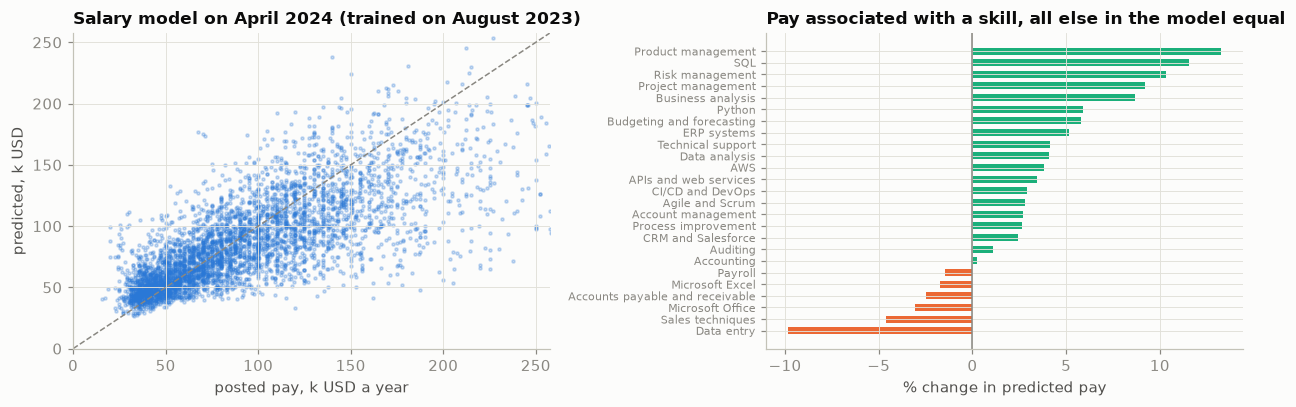

In [17]:
# The skill premium the model implies: switch a skill on for every test posting, average the change in log pay
Xt = Xs_sk[te].copy(); base_pred = m_sk.predict(Xt)
premium = {}
for s in demand[demand.kind.isin(OFFER_KINDS)].sort_values("share_apr", ascending=False).index[:25]:
    col = "skill_" + slug(s); X1 = Xt.copy(); X1[col] = 1
    premium[s] = float(np.exp(np.mean(m_sk.predict(X1) - base_pred)) - 1)
demand["premium"] = pd.Series(premium)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
p_te = np.exp(m_sk.predict(Xs_sk[te])); a_te = sal.annual.values[te]
ax.scatter(a_te / 1e3, p_te / 1e3, s=4, alpha=0.25, color=SERIES[0])
lim = np.percentile(np.r_[a_te, p_te], 99) / 1e3
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("posted pay, k USD a year"); ax.set_ylabel("predicted, k USD")
ax.set_title("Salary model on April 2024 (trained on August 2023)")
ax = axes[1]
pr = demand.premium.dropna().sort_values()
ax.barh(pr.index, 100 * pr.values, color=[SERIES[1] if v < 0 else SERIES[2] for v in pr.values], height=0.6)
ax.axvline(0, color=MUTED, lw=1); ax.set_xlabel("% change in predicted pay"); ax.tick_params(axis="y", labelsize=7)
ax.set_title("Pay associated with a skill, all else in the model equal")
plt.tight_layout()

**The operating point comes from capacity, not a threshold.** Candidates are teachable skills (digital, office, business, design) the provider does not teach yet; the rule ranks them by April demand and checks how often each lands in the top six across the employer bootstrap. Growth and pay premium are shown, not used: their intervals are too wide to rank on (Trap 4).

,share_apr,lo,hi,change_pp,change_lo,change_hi,p_top,premium,esco
Process improvement,8.2%,7.6%,8.8%,-0.1,-1.1,+0.8,100%,+2.6%,close
Account management,5.7%,5.2%,6.1%,+0.1,-0.4,+0.8,100%,+2.7%,close
ERP systems,4.9%,4.5%,5.3%,-0.7,-1.3,+0.1,100%,+5.1%,close
CRM and Salesforce,4.8%,4.4%,5.2%,-0.7,-1.3,-0.1,100%,+2.4%,close
SQL,4.5%,4.1%,5.0%,-0.8,-1.5,+0.0,86%,+11.6%,exact
Budgeting and forecasting,4.5%,4.1%,4.9%,-0.2,-0.7,+0.4,92%,+5.8%,close
Risk management,4.1%,3.7%,4.6%,-0.1,-0.7,+0.5,18%,+10.3%,exact
Business analysis,4.0%,3.7%,4.4%,-0.1,-0.6,+0.5,4%,+8.7%,exact
Sales techniques,3.5%,3.1%,3.9%,-0.2,-0.8,+0.5,0%,-4.6%,close
Data entry,3.4%,3.1%,4.0%,-0.1,-0.6,+0.6,0%,-9.8%,close


64% of April postings ask for at least one teachable skill; the current offer touches 62% of those, and 77% with the 6 additions: Process improvement, Account management, ERP systems, CRM and Salesforce, SQL, Budgeting and forecasting


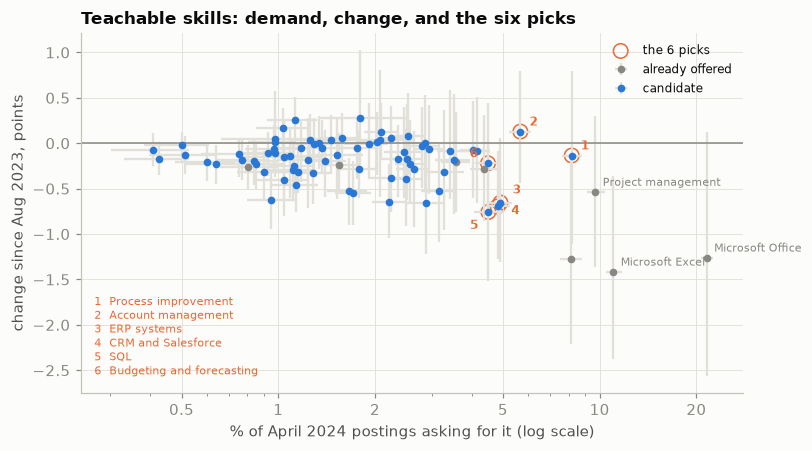

In [18]:
cand = demand[demand.kind.isin(OFFER_KINDS) & ~demand.offered]
ranks = np.argsort(np.argsort(-boot_apr[:, [S_IDX[s] for s in cand.index]], axis=1), axis=1)
cand = cand.assign(p_top=(ranks < MODULES_PER_YEAR).mean(0))
pick = cand.sort_values("share_apr", ascending=False).head(MODULES_PER_YEAR)
display(cand.sort_values("share_apr", ascending=False).head(10)[["share_apr", "lo", "hi", "change_pp", "change_lo", "change_hi", "p_top", "premium", "esco"]]
        .style.format({"share_apr": "{:.1%}", "lo": "{:.1%}", "hi": "{:.1%}", "change_pp": "{:+.1f}", "change_lo": "{:+.1f}",
                       "change_hi": "{:+.1f}", "p_top": "{:.0%}", "premium": "{:+.1%}"}, na_rep="–"))

teach = [S_IDX[s] for s in skills.skill[skills.kind.isin(OFFER_KINDS)]]
asks = np.asarray(X_apr[:, teach].sum(1)).ravel() > 0
def coverage(offer):
    cols = [S_IDX[s] for s in offer]
    return float((np.asarray(X_apr[:, cols].sum(1)).ravel() > 0)[asks].mean())
print(f"{asks.mean():.0%} of April postings ask for at least one teachable skill; the current offer touches {coverage(CURRENT_OFFER):.0%} of those, "
      f"and {coverage(CURRENT_OFFER | set(pick.index)):.0%} with the {MODULES_PER_YEAR} additions: {', '.join(pick.index)}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
d = demand[demand.kind.isin(OFFER_KINDS) & (demand.share_apr > 0)]
for offered, color, label in [(True, MUTED, "already offered"), (False, SERIES[0], "candidate")]:
    q = d[d.offered == offered]
    ax.errorbar(100 * q.share_apr, q.change_pp, xerr=[100 * (q.share_apr - q.lo), 100 * (q.hi - q.share_apr)],
                yerr=[q.change_pp - q.change_lo, q.change_hi - q.change_pp], fmt="o", ms=4, color=color, ecolor=GRID, label=label)
for k, s in enumerate(pick.index, start=1):
    ax.annotate(str(k), (100 * d.share_apr[s], d.change_pp[s]), xytext=[(6, 4), (6, 4), (8, 6), (9, -5), (-12, -11), (-12, 4)][(k - 1) % 6],
                textcoords="offset points", fontsize=8, color=SERIES[1], weight="bold")
for s in [s for s in d.sort_values("share_apr").index[-4:] if s not in pick.index]:
    ax.annotate(s, (100 * d.share_apr[s], d.change_pp[s]), xytext=(5, 4), textcoords="offset points", fontsize=7, color=MUTED)
ax.text(0.02, 0.04, "\n".join(f"{k}  {s}" for k, s in enumerate(pick.index, start=1)), transform=ax.transAxes, fontsize=7.5,
        color=SERIES[1], va="bottom")
ax.scatter(100 * pick.share_apr, pick.change_pp, s=90, facecolors="none", edgecolors=SERIES[1], label=f"the {MODULES_PER_YEAR} picks")
ax.axhline(0, color=MUTED, lw=1); ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10, 20]); ax.set_xticklabels(["0.5", "1", "2", "5", "10", "20"])
ax.set_xlabel("% of April 2024 postings asking for it (log scale)"); ax.set_ylabel("change since Aug 2023, points")
ax.set_title("Teachable skills: demand, change, and the six picks"); ax.legend(fontsize=8)
plt.tight_layout()

**The answer to the board.** Teach process improvement, account management, ERP systems, CRM and Salesforce, SQL, and budgeting and forecasting. Today the catalogue touches 62 % of the April postings that ask for a teachable skill; with these six, 77 %. Four of the six are in the top six in every employer resample, budgeting in 92 % and SQL in 86 %; the next contender, risk management, in 18 %. None grew measurably since August 2023 (account management +0.1 points, inside its interval; CRM fell by 0.7): a demand-led choice. SQL, risk management and business analysis carry the largest premiums among the leading ten (+11.6 %, +10.3 %, +8.7 %); a board weighing pay over volume would swap one module (task C3).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four things a careless version of this notebook would do, each measured against the honest number.

**Trap 1 — Reposts and copies.** 13.3 % of April postings repeat another's text and 8.6 % are re-listings; one employer (J. Galt) has 604 postings with 19 distinct texts. Counted per posting, cash handling climbs from 61st to 35th among skills. A random salary split puts copies on both sides (8 % of test rows): MAE $25,796 against $26,557 holding out whole employers, but over three seeds the ranges overlap ($25,796–26,604 against $24,503–26,669). The salary leak is within split noise here; the count distortion is not.

In [19]:
apr_posts = posts[posts.wave == TEST_WAVE]
mult = apr_posts.groupby("desc_hash").size()
rep = apr_posts.groupby("company_name").agg(postings=("job_id", "size"), distinct=("desc_hash", "nunique"))
rep["copies"] = rep.postings - rep.distinct
print(f"April 2024: {1 - apr_posts.desc_hash.nunique() / len(apr_posts):.1%} of postings repeat another's text; "
      f"{(apr_posts.original_listed_time < apr_posts.listed_time - pd.Timedelta(days=1)).mean():.1%} are re-listings of an older posting")
display(rep.sort_values("copies", ascending=False).head(5))

w = apr_all.desc_hash.map(mult).fillna(1).values.astype(np.float32)        # how many postings carry each sampled text
naive = pd.Series((X_apr.T @ w) / w.sum(), index=SKILLS)
cmp_ = pd.DataFrame({"per posting (naive)": naive, "per distinct text": share_apr})
cmp_["rank naive"] = cmp_["per posting (naive)"].rank(ascending=False).astype(int)
cmp_["rank distinct"] = cmp_["per distinct text"].rank(ascending=False).astype(int)
cmp_["diff_pp"] = 100 * (cmp_["per posting (naive)"] - cmp_["per distinct text"])
display(cmp_.reindex(cmp_.diff_pp.abs().sort_values(ascending=False).index).head(6).style.format(
    {"per posting (naive)": "{:.1%}", "per distinct text": "{:.1%}", "diff_pp": "{:+.1f}"}))

# salary: every April posting whose text is in the sample, copies included, split two ways
dup = posts[(posts.wave == TEST_WAVE) & posts.desc_hash.isin(set(apr_all.desc_hash)) & posts.pay_period.isin(list(PERIODS_PER_YEAR))].copy()
dup["annual"] = annualise(dup); dup = dup[dup.annual.between(MIN_ANNUAL, MAX_ANNUAL)].reset_index(drop=True)
row_of = dict(zip(apr_all.desc_hash, range(len(apr_all))))
Xd = features(dup, True, X_apr[[row_of[h] for h in dup.desc_hash]]); yd = np.log(dup.annual.values)
def holdout_mae(i_tr, i_te):
    m = lgb.LGBMRegressor(**{**LGB_PARAMS, "n_estimators": m_sk.best_iteration_}).fit(Xd.iloc[i_tr], yd[i_tr])
    return float(np.mean(np.abs(np.exp(m.predict(Xd.iloc[i_te])) - dup.annual.values[i_te])))
spread = []
for sd in (SEED, SEED + 1, SEED + 2):                       # three split seeds: the two splits use different test rows
    i_tr, i_te = train_test_split(np.arange(len(dup)), test_size=0.25, random_state=sd)
    g_tr, g_te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=sd).split(dup, groups=dup.company_key))
    spread.append((holdout_mae(i_tr, i_te), holdout_mae(g_tr, g_te), dup.desc_hash.iloc[i_te].isin(set(dup.desc_hash.iloc[i_tr])).mean()))
spread = np.array(spread)
print(f"April salaried postings incl. copies: {len(dup):,} · seed {SEED}: random split MAE {spread[0, 0]:,.0f} USD "
      f"({spread[0, 2]:.0%} of test rows have their text in training), split by company {spread[0, 1]:,.0f} USD · "
      f"three seeds: random {spread[:, 0].min():,.0f}–{spread[:, 0].max():,.0f}, by company {spread[:, 1].min():,.0f}–{spread[:, 1].max():,.0f}")

April 2024: 13.3% of postings repeat another's text; 8.6% are re-listings of an older posting


,postings,distinct,copies
company_name,,,
J. Galt,604,19,585
"Lowe's Companies, Inc.",527,127,400
Cogent Communications,476,87,389
Ingersoll Rand,517,177,340
Capital One,496,194,302


,per posting (naive),per distinct text,rank naive,rank distinct,diff_pp
Cash handling and POS,3.3%,2.1%,35,61,+1.2
Customer service,22.3%,21.3%,2,4,+1.1
Problem solving,20.7%,21.5%,4,3,-0.8
Microsoft Excel,10.3%,11.0%,8,8,-0.7
Attention to detail,15.5%,16.2%,6,6,-0.7
Time management,18.6%,19.3%,5,5,-0.7


April salaried postings incl. copies: 4,913 · seed 3217: random split MAE 25,796 USD (8% of test rows have their text in training), split by company 26,557 USD · three seeds: random 25,796–26,604, by company 24,503–26,669


**Trap 2 — A salary for a third of postings, in five pay periods.** 29 % of April postings carry a salary. Across the waves, 543 "YEARLY" salaries are below $15,080 (median posted value 55: an hourly rate in the wrong box) and 36 "HOURLY" ones exceed $1M once annualised. Averaging `max_salary` across periods gives $91,089; annualising everything, $188,374; annualising the plausible values, $96,525.

Who posts a salary is not random: half the postings in the four states whose posting-range laws applied in all three waves (California, Colorado, New York, Washington; Hawaii's began in January 2024), 22 % elsewhere. Those states are 31 % of salaried postings but 18 % of all; patient care is 35 % rarer among salaried postings, accounting 29 % more common. The salary model describes postings that publish pay, not the market.

In [20]:
allsal = posts[posts.pay_period.notna()].copy(); allsal["annual"] = annualise(allsal)
bad_y = allsal[(allsal.pay_period == "YEARLY") & (allsal.annual < MIN_ANNUAL)]
bad_h = allsal[(allsal.pay_period == "HOURLY") & (allsal.annual > MAX_ANNUAL)]
print(f"'YEARLY' pay below {MIN_ANNUAL:,} USD: {len(bad_y)} postings (median posted value {bad_y.med_salary.fillna(bad_y.max_salary).median():.0f}, "
      f"an hourly rate typed in the wrong box) · 'HOURLY' pay above {MAX_ANNUAL:,} USD a year once annualised: {len(bad_h)}")
print(f"naive mean of max_salary across periods: {allsal.max_salary.mean():,.0f} · mean annualised, all: {allsal.annual.mean():,.0f} · "
      f"mean annualised, plausible only: {allsal.annual[allsal.annual.between(MIN_ANNUAL, MAX_ANNUAL)].mean():,.0f} USD")

# selection: who posts a salary
a4 = posts[posts.wave == TEST_WAVE].copy()
a4["salaried"] = a4.pay_period.notna(); a4["transparency_state"] = a4.state.isin(TRANSPARENCY_STATES)
print(f"April: salary posted by {a4.salaried[a4.transparency_state].mean():.0%} of postings in CA, CO, NY, WA vs "
      f"{a4.salaried[~a4.transparency_state & a4.state.notna()].mean():.0%} in other states; those four states are "
      f"{a4.transparency_state[a4.salaried].mean():.0%} of salaried postings and {a4.transparency_state.mean():.0%} of all")
print(f"Hawaii (law in force from January 2024, so not in the four): salary on {a4.salaried[a4.state == 'HI'].mean():.0%} "
      f"of its {(a4.state == 'HI').sum()} April postings")
sal_apr = apr_all.pay_period.notna().values
sel = pd.DataFrame({"all April postings": np.asarray(X_apr.mean(0)).ravel(), "salaried only": np.asarray(X_apr[sal_apr].mean(0)).ravel()}, index=SKILLS)
sel["ratio"] = sel["salaried only"] / sel["all April postings"]
display(sel.loc[demand.sort_values("share_apr", ascending=False).index[:30]].sort_values("ratio").iloc[[0, 1, 2, -3, -2, -1]]
        .style.format({"all April postings": "{:.1%}", "salaried only": "{:.1%}", "ratio": "{:.2f}"}))

'YEARLY' pay below 15,080 USD: 543 postings (median posted value 55, an hourly rate typed in the wrong box) · 'HOURLY' pay above 1,000,000 USD a year once annualised: 36
naive mean of max_salary across periods: 91,089 · mean annualised, all: 188,374 · mean annualised, plausible only: 96,525 USD
April: salary posted by 50% of postings in CA, CO, NY, WA vs 22% in other states; those four states are 31% of salaried postings and 18% of all
Hawaii (law in force from January 2024, so not in the four): salary on 39% of its 425 April postings


,all April postings,salaried only,ratio
Patient care,7.8%,5.1%,0.65
CPR and life support,7.3%,5.2%,0.71
Workplace safety,4.8%,4.2%,0.89
CRM and Salesforce,4.8%,5.9%,1.22
Negotiation,4.4%,5.4%,1.23
Accounting,8.2%,10.5%,1.29


**Trap 3 — The "skills" file holds LinkedIn's job-function labels, not skills.** `jobs/job_skills.csv` holds 35 values such as *Information Technology*, *Sales* and *Health Care Provider*, at most three per posting: in our reading, LinkedIn's job-function field, a category rather than a skill. The 3,169 April postings labelled Information Technology show 1,179 distinct combinations of digital skills, from help desks to C#/.NET engineering, and communication is their most common skill. Against this field the extractor scores 0.27; against a person's labels, 0.62.

In [21]:
it = apr_all[apr_all.functions.str.contains(r"\bIT\b", regex=True)]
X_it = to_matrix(it.job_id)
top_it = pd.Series(np.asarray(X_it.mean(0)).ravel(), index=SKILLS).sort_values(ascending=False)
DIGITAL = set(skills.skill[skills.kind == "digital"])
profiles = pd.Series(["|".join(sorted(res[j]["base"] & DIGITAL)) for j in it.job_id])
print(f"April postings labelled 'Information Technology': {len(it):,} ({len(it)/len(apr_all):.0%} of the sample); "
      f"{profiles.nunique():,} distinct combinations of digital skills among them")
print("their most frequent extracted skills:", ", ".join(f"{s} {v:.0%}" for s, v in top_it.head(10).items()))
print(f"one label covers a help-desk role and a C#/.NET engineer alike; evaluated against the labels the extractor scores "
      f"micro-F1 {label_eval:.2f}, against skills a person marked {gold_eval['F1']:.2f}")

April postings labelled 'Information Technology': 3,169 (21% of the sample); 1,179 distinct combinations of digital skills among them
their most frequent extracted skills: Communication 41%, Problem solving 27%, Troubleshooting 22%, Microsoft Office 18%, Project management 15%, Time management 15%, SQL 14%, Customer service 14%, Attention to detail 14%, Teamwork 13%
one label covers a help-desk role and a C#/.NET engineer alike; evaluated against the labels the extractor scores micro-F1 0.27, against skills a person marked 0.62


**Trap 4 — Three short windows are not a time series.** The waves span 15, 5 and 16 days. Splitting April into 5–17 and 18–20 April moves the top-40 skill shares by 0.60 points on average; August to November, 0.52; August to April, 0.68. The label mix moved too (health care 9 % → 14 %): naively CPR and life support grew by 3.2 points and patient care by 2.6, at August's mix by 1.4 and 0.6. "Growth" from three snapshots is mostly sampling and composition.

In [22]:
halves = apr_all.listed_time < "2024-04-18"
Xh1, Xh2 = to_matrix(apr_all.job_id[halves]), to_matrix(apr_all.job_id[~halves])
top40 = demand.sort_values("share_apr", ascending=False).index[:40]
idx40 = [S_IDX[s] for s in top40]
def mean_abs_pp(A, B):
    return float(100 * np.mean(np.abs(np.asarray(A[:, idx40].mean(0)).ravel() - np.asarray(B[:, idx40].mean(0)).ravel())))
nov = sample[sample.wave == VALID_WAVE]; X_nov = to_matrix(nov.job_id)
print(f"mean absolute change in the top-40 skill shares · April 5–17 vs 18–20 (same month): {mean_abs_pp(Xh1, Xh2):.2f} points · "
      f"Aug vs Nov 2023: {mean_abs_pp(X_aug, X_nov):.2f} · Aug 2023 vs Apr 2024: {mean_abs_pp(X_aug, X_apr):.2f}")

def group_of(fs):
    s = set(fs.split("|"))
    for gname, members in [("health", {"HCPR"}), ("IT and engineering", {"IT", "ENG"}), ("sales and marketing", {"SALE", "BD", "MRKT", "ADVR", "CUST"}),
                           ("finance", {"FIN", "ACCT"}), ("production and supply", {"MNFC", "PROD", "QA", "SUPL", "DIST", "PRCH"})]:
        if s & members:
            return gname
    return "other"
mix_aug = seed.functions.map(group_of).value_counts(normalize=True); mix_apr = apr_all.functions.map(group_of).value_counts(normalize=True)
print("label-group mix, Aug 2023 → Apr 2024:", {k: f"{mix_aug.get(k, 0):.0%}→{mix_apr.get(k, 0):.0%}" for k in mix_apr.index})
wt = apr_all.functions.map(group_of).map(mix_aug / mix_apr).fillna(1).values.astype(np.float32)   # re-weight April to August's mix
adj = pd.Series((X_apr.T @ wt) / wt.sum(), index=SKILLS)
growth = pd.DataFrame({"naive change, pp": 100 * (share_apr - share_seed), "same label mix as Aug, pp": 100 * (adj - share_seed)})
display(growth.loc[growth["naive change, pp"].abs().sort_values(ascending=False).index[:6]].round(2))

mean absolute change in the top-40 skill shares · April 5–17 vs 18–20 (same month): 0.60 points · Aug vs Nov 2023: 0.52 · Aug 2023 vs Apr 2024: 0.68
label-group mix, Aug 2023 → Apr 2024: {'IT and engineering': '27%→24%', 'other': '23%→21%', 'sales and marketing': '19%→20%', 'production and supply': '15%→16%', 'health': '9%→14%', 'finance': '6%→5%'}


,"naive change, pp","same label mix as Aug, pp"
CPR and life support,3.22,1.35
Patient care,2.65,0.60
Nursing licence,1.84,0.74
Microsoft Excel,-1.42,-0.82
Communication,-1.35,-0.41
Customer service,1.28,1.19


For the board: shares are good to about half a point, rankings to a few places, growth not at all.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · Drift: the skill mix across waves, and what the dictionary cannot place

*Part C · Productionise · what your monitoring plan must catch; reuse `unplaced_by_wave` and `js` (C5).*

The card's drift signal is the share of skill phrases the dictionary cannot place: a dictionary frozen in August 2023 should leave more of 2024's vocabulary unplaced if new tools appear. Only *recurring* phrases count (used by at least ten employers in the wave), to keep one employer's template out. Two more views: the skill-mix divergence between and within waves, and one watch-list term, generative AI, counted on every distinct posting.

,recurring phrases,unplaced,lo,hi,gen-AI postings,distinct postings,gen-AI share
2023-08,552,57.9%,57.1%,58.9%,48,"13,831",0.35%
2023-11,540,56.7%,55.9%,57.5%,68,"16,252",0.42%
2024-04,575,58.9%,58.0%,59.8%,627,"107,415",0.58%


April unplaced share of recurring phrases: {'dictionary v1 (actual)': '58.9%', 'simulated: no cloud and DevOps entries (7)': '61.6%', 'simulated: no spreadsheet or office entries (4)': '68.7%', 'simulated: no digital entries (42)': '76.4%'}
the most frequent recurring phrases the dictionary cannot place (its to-do list):


,word,outlook,sales,engineering,writing,marketing,finance,english,manufacturing,electrical,ci,maintenance
Apr 2024 postings,474,214,174,108,106,102,100,85,83,78,74,73
Aug 2023 postings,552,214,162,81,61,90,99,88,72,59,54,69


Jensen–Shannon × 1,000: {'Apr 5–17 vs Apr 18–20': 1.78, 'Aug 2023 vs Nov 2023': 1.75, 'Nov 2023 vs Apr 2024': 1.28, 'Aug 2023 vs Apr 2024': 2.98}


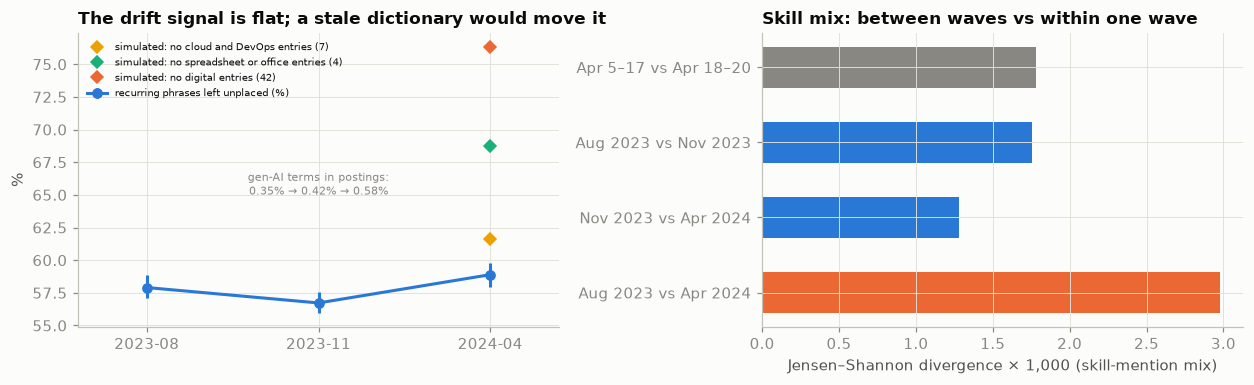

In [23]:
def unplaced_by_wave():
    out = {}
    for w_, d_ in sample.groupby("wave"):
        vocab, ids = recurring(d_), d_.job_id.values
        num = np.array([sum(x in vocab for x in res[j]["unplaced_base"]) for j in ids])
        den = np.array([sum(x in vocab for x in res[j]["cand"]) for j in ids])
        r_ = np.random.default_rng(SEED); bs = []
        for _ in range(N_BOOT):
            i = r_.integers(0, len(ids), len(ids)); bs.append(num[i].sum() / den[i].sum())
        out[w_] = {"recurring phrases": len(vocab), "unplaced": num.sum() / den.sum(), "lo": np.percentile(bs, 2.5), "hi": np.percentile(bs, 97.5)}
    return pd.DataFrame(out).T

# the watch-list term on every distinct posting, not only the sample (RE2 through pyarrow: seconds)
wave_of = dist.set_index("job_id").wave.to_dict(); gen_hits = Counter(); gen_n = Counter()
for batch in pq.ParquetFile(TEXT_PATH).iter_batches(batch_size=20_000):
    hit = pc.match_substring_regex(batch.column(1), GENAI.pattern).to_numpy(zero_copy_only=False)
    for j, h in zip(batch.column(0).to_pylist(), hit):
        if j in wave_of:
            gen_n[wave_of[j]] += 1; gen_hits[wave_of[j]] += int(h)
drift = unplaced_by_wave()
drift["gen-AI postings"] = pd.Series(gen_hits); drift["distinct postings"] = pd.Series(gen_n)
drift["gen-AI share"] = drift["gen-AI postings"] / drift["distinct postings"]
display(drift.style.format({"recurring phrases": "{:,.0f}", "unplaced": "{:.1%}", "lo": "{:.1%}", "hi": "{:.1%}", "gen-AI postings": "{:,.0f}",
                            "distinct postings": "{:,.0f}", "gen-AI share": "{:.2%}"}))

# SIMULATED (labelled): how far the signal moves when the dictionary lacks a block of entries
CLOUD = {"Docker", "Kubernetes", "CI/CD and DevOps", "Infrastructure as code", "AWS", "Microsoft Azure", "Google Cloud"}
VOCAB_APR = recurring(apr_all)
sim = {"dictionary v1 (actual)": unplaced_rate(apr_all.job_id, "base", VOCAB_APR)}
for name, drop in [("simulated: no cloud and DevOps entries (7)", CLOUD),
                   ("simulated: no spreadsheet or office entries (4)", set(skills.skill[skills.kind == "office"])),
                   ("simulated: no digital entries (42)", set(skills.skill[skills.kind == "digital"]))]:
    sim[name] = unplaced_rate(apr_all.job_id, "base", VOCAB_APR, Extractor(table=skills[~skills.skill.isin(drop)]))
sim = pd.Series(sim)
print("April unplaced share of recurring phrases:", {k: f"{v:.1%}" for k, v in sim.items()})

def unplaced_counts(df, vocab):
    c = Counter()
    for j in df.job_id:
        c.update({x for x in res[j]["unplaced_base"] if x in vocab})
    return c
todo = pd.DataFrame({"Apr 2024 postings": pd.Series(unplaced_counts(apr_all, VOCAB_APR)),
                     "Aug 2023 postings": pd.Series(unplaced_counts(seed, recurring(seed)))}).fillna(0).astype(int)
print("the most frequent recurring phrases the dictionary cannot place (its to-do list):")
display(todo.sort_values("Apr 2024 postings", ascending=False).head(12).T)

def js(p, q):
    p, q = p / p.sum(), q / q.sum(); m = (p + q) / 2
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log(a / b), 0))
    return float((kl(p, m) + kl(q, m)) / 2)
mention = lambda Xm: np.asarray(Xm.sum(0)).ravel() + 1e-9
js_tbl = pd.Series({"Apr 5–17 vs Apr 18–20": js(mention(Xh1), mention(Xh2)), "Aug 2023 vs Nov 2023": js(mention(X_aug), mention(X_nov)),
                    "Nov 2023 vs Apr 2024": js(mention(X_nov), mention(X_apr)), "Aug 2023 vs Apr 2024": js(mention(X_aug), mention(X_apr))})

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax = axes[0]
xw = np.arange(len(drift))
ax.errorbar(xw, 100 * drift.unplaced.astype(float), yerr=[100 * (drift.unplaced - drift.lo).astype(float), 100 * (drift.hi - drift.unplaced).astype(float)],
            fmt="-o", color=SERIES[0], lw=2, label="recurring phrases left unplaced (%)")
for (name, v), c in zip(list(sim.items())[1:], [SERIES[3], SERIES[2], SERIES[1]]):
    ax.plot([len(drift) - 1], [100 * v], "D", color=c, ms=6, label=name)
ax.set_xticks(xw); ax.set_xticklabels(drift.index); ax.set_ylabel("%"); ax.set_xlim(-0.4, len(drift) - 0.6)
ax.set_title("The drift signal is flat; a stale dictionary would move it"); ax.legend(fontsize=6.5, loc="upper left")
ax.text(0.5, 0.45, "gen-AI terms in postings:\n" + " → ".join(f"{v:.2%}" for v in drift["gen-AI share"]), transform=ax.transAxes,
        ha="center", fontsize=7.5, color=MUTED)
ax = axes[1]
ax.barh(js_tbl.index, js_tbl.values * 1000, color=[MUTED, SERIES[0], SERIES[0], SERIES[1]], height=0.55)
ax.invert_yaxis(); ax.set_xlabel("Jensen–Shannon divergence × 1,000 (skill-mention mix)")
ax.set_title("Skill mix: between waves vs within one wave")
plt.tight_layout()
print("Jensen–Shannon × 1,000:", (js_tbl * 1000).round(2).to_dict())

Nothing in eight months stands out from the collection noise. The unplaced share moves within a 2.2-point band (56.7–58.9 %); November's and April's intervals do not overlap, so posting-level intervals understate the noise between waves and the band is the yardstick. Consecutive waves diverge in skill mix (Jensen–Shannon 1.75 and 1.28 × 10⁻³) as much as April's halves (1.78); August to April, 1.7 times as much (2.98), partly the label mix (Trap 4). The *labelled simulation* shows what the signal can see: without its seven cloud and DevOps entries the dictionary would read 61.6 % in April, close to a wobble; without its four office entries, 68.7 %. Gen-AI terms rose from 0.35 % of August postings to 0.58 % of April's (48 to 627), too few to move an aggregate: they need a watch-list. The to-do list is the most useful output: "word", "outlook" and "ci" are skills the dictionary refuses out of context; "sales" and "finance" are fields.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's table, updated with what this notebook found:

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/skills_intel/` (`normalise`, `extract`, `esco`, `salary`, `report`); versioned dictionary file; monthly report job; `POST /extract` returning skills and ESCO URIs |
| Monitoring (S04) | Unplaced share of recurring phrases (band 56.7–58.9 %; a missing office block reads 68.7 %); postings with no skill (6.1 %); copy rate (13 %); salary coverage (29 %); salary MAE per wave |
| CI/CD gate (S05) | Frozen, fingerprinted sets: extraction F1 ≥ 0.54, the lower end of its interval (0.62 on the gold set, SHA-256 `79fda90a296b`); salary MAE ≤ $27,000, set on validation, where the no-skills model scores $26,802 (25,809 on April, `41e8d1169f02`); SHACL; "excel in" yields no skill |
| MLflow tracking and registry (S06) | Dictionary and ESCO versions and hashes, seed, LightGBM parameters, gold-set and holdout fingerprints; `champion` dictionary and model |
| Offline / online training and serving | Offline monthly batch per wave; online extraction under 2 ms per posting (regex, one core); dictionary releases on a schedule; salary model retrained per wave |
| Data and model drift | Nothing measurable in eight months: unplaced share 57.9 → 56.7 → 58.9 %; consecutive waves diverge as much as April's halves; gen-AI terms 0.35 → 0.58 % of postings; health care 9 → 14 % of the mix |
| Knowledge base and context (S07–S09) | 138 skills aligned to 126 ESCO v1.2.1 concepts (53 exact, 65 close, 16 broad or narrow, 4 none), 70 groups, 35 LinkedIn labels; 1,743 triples; four shapes. Ablation: ESCO labels: precision 0.94 → 0.87, recall 0.46 → 0.51, F1 gain within noise |
| GenAI and context engineering (S10–S11) | Career and curriculum assistant over the graph and cited postings; golden set from the graph; never ranks people |
| Governance | Postings: CC BY-SA 4.0, scraped from LinkedIn (provenance ADR, ShareAlike on derived tables). ESCO v1.2.1: reused under Decision 2011/833/EU with the acknowledgement. Market analytics only: ranking candidates falls under AI Act Annex III point 4. Recruiter contacts masked; no posting text printed |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Deduplicate on text before counting (a test fails if a text counts twice); split salaries by employer; annualise with the plausibility rule and log drops; keep LinkedIn's labels out of skill evaluation; report growth with its interval at a fixed label mix.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `MODULES_PER_YEAR` (3–12), the catalogue, `OFFER_KINDS` and a rule weighting pay or growth; show how the six change; write the ADR for the programme board.
- **C4 — Package, container and gate (Sessions 02, 03, 05).** `POST /extract` and the report job in a container; `make ci` runs lint, tests and SHACL, then gates on extraction precision and F1 over a frozen, fingerprinted gold set of 200+ postings labelled by two people (Cohen's κ) and on salary MAE over the fingerprinted April holdout.
- **C5 — Register, document, monitor (Sessions 04, 06).** MLflow runs with dictionary and ESCO versions; a `champion` alias; a model card (US, scraped, three waves, salaried subset, one annotator); a monitoring plan with the unplaced share and its band, copy rate and a dictionary-release trigger.

### Extension

- **E1 — The knowledge-base ablation, done properly (Sessions 07–09).** Use ESCO's structure: aggregate demand to ESCO groups, propose entries from ESCO occupations, drop ambiguous labels such as "R". On the C4 gold set, does ESCO context change the six?
- **E2 — Provenance and data protection.** The ADR: what CC BY-SA can grant for content scraped from a platform with its own user agreement; ShareAlike on derived tables; ESCO's reuse terms; GDPR for recruiters' names, as questions for the data-protection officer. Count the names the masking misses in 100 postings.
- **E3 — Fairness of the market view.** Re-weight the salary analysis from the salaried postings to the full posting mix (states, occupations) and show which premiums move.
- **E4 — A local catalogue.** Map a real programme's learning outcomes to ESCO and compare with the six; what can a US market not tell a Maltese provider?

### Stretch

- **S1 — Career and curriculum assistant (Sessions 10–11).** Answer "what should a junior data analyst learn next?" from the graph and cited postings: versioned prompt, structured output (ESCO URIs, posting ids), 50 golden questions from the graph, citation, injection and cost tests. It never ranks candidates.
- **S2 — Online extraction and its cost.** Serve `POST /extract`, replay the busiest listing day (18 April 2024), report p95 latency and cost against the batch.
- **S3 — A drift alert worth having.** Set the alert threshold and release cadence from the band and the simulated stale dictionaries of Section 7; test it on gen-AI vocabulary planted in a held-out wave.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; no posting text or contacts in fixtures or logs
- [ ] `README.md`: sources (Kaggle versions 13 and 9, CC BY-SA 4.0, scraped), ESCO version and acknowledgement, waves, sampling rule
- [ ] Copies removed before counting; salaries annualised and filtered; employer splits; LinkedIn labels never used as skills
- [ ] Dictionary, gold set and ESCO subset versioned and fingerprinted; `make ci` with extraction, salary and SHACL gates
- [ ] Provenance ADR, AI Act position, the six modules with their stability and assumptions
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No LLM, no GPU.
- Koneru, A. (2024). *LinkedIn Job Postings (2023–2024)*, Kaggle, CC BY-SA 4.0, versions 9 and 13; scraper at `github.com/ArshKA/LinkedIn-Job-Scraper`.
- European Commission. *ESCO*, v1.2.1, and its web-service API, reused under Commission Decision 2011/833/EU on the reuse of Commission documents. *This service uses the ESCO classification of the European Commission.*
- Regulation (EU) 2016/589 (EURES), Art. 19; Regulation (EU) 2024/1689 (AI Act), Annex III, point 4.
- Posting-range laws: Colorado SB 19-085 (2021), California SB 1162 (2023), Washington SB 5761 (2023), New York Labor Law § 194-b (Sept. 2023), Hawaii SB 1057 (2024).
- W3C (2009). *SKOS Reference*; W3C (2017). *SHACL*. Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 4 and 8.

In [24]:
import matplotlib
print(f"pandas {pd.__version__} · numpy {np.__version__} · pyarrow {pa.__version__} · scikit-learn {sklearn.__version__} · lightgbm {lgb.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__} · matplotlib {matplotlib.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · pyarrow 26.0.0 · scikit-learn 1.9.1 · lightgbm 4.7.0 · rdflib 7.6.0 · pyshacl 0.40.1 · matplotlib 3.11.2
notebook finished · total wall time 111s
